
# WeIntern Data Science Internship — Week 1 Assignment

**Author:** Rishi Kuber  
**Environment:** Jupyter Notebook / Anaconda

## Dataset Information

This project uses a synthetic educational e-commerce sales dataset. It is intended for learning and demonstrating data-cleaning, exploratory data analysis, and data-visualization techniques. It does not represent real company data.

## Objectives

1. Clean and validate the raw e-commerce sales dataset.
2. Calculate key sales performance indicators (KPIs).
3. Analyze sales trends, product performance, and customer insights.
4. Create bar, line, and pie charts, along with a dashboard mockup.
5. Document findings, cleaning decisions, assumptions, and limitations.


In [1]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

# Task 1: Load and inspect the raw dataset

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_DATA_PATH = PROJECT_DIR / "data" / "raw" / "ecommerce_sales_raw.csv"

if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {RAW_DATA_PATH}\n"
        "Make sure the notebook is inside the project's notebooks folder "
        "and the original folder structure is unchanged."
    )

df_raw = pd.read_csv(RAW_DATA_PATH)

print("Dataset loaded successfully.")
print(f"Rows: {df_raw.shape[0]}")
print(f"Columns: {df_raw.shape[1]}")

display(df_raw.head())


Dataset loaded successfully.
Rows: 662
Columns: 11


,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD-10001,CUST-1019,T-Shirt,Fashion,3,599.0,1797.0,2025-02-02,UPI,Delivered,Pune
1,ORD-10002,NaN,Shampoo,Beauty,2,299.0,598.0,2025-10-10,UPI,Shipped,Bengaluru
2,ORD-10003,CUST-1043,Smart Watch,Electronics,4,2499.0,9996.0,2025-08-27,Debit Card,Shipped,Hyderabad
3,ORD-10004,CUST-1237,Shampoo,Beauty,4,299.0,1196.0,2025-06-10,UPI,Delivered,Surat
4,ORD-10005,CUST-1170,Wireless Earbuds,Electronics,2,1299.0,2598.0,2025-06-08,Cash on Delivery,Shipped,Delhi


In [3]:

# Task 1: Raw Dataset Inspection

print("DATASET STRUCTURE")
print("-" * 50)
print("Number of rows:", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])

print("\nCOLUMN NAMES")
print("-" * 50)
print(df_raw.columns.tolist())

print("\nDATA TYPES")
print("-" * 50)
display(df_raw.dtypes.to_frame(name="Data Type"))

print("\nDATASET INFORMATION")
print("-" * 50)
df_raw.info()

print("\nFIRST 5 ROWS")
print("-" * 50)
display(df_raw.head())

print("\nNUMERICAL SUMMARY")
print("-" * 50)
display(df_raw.describe(include="all").T)

print("\nRAW DATASET MEMORY USAGE")
print("-" * 50)
print(f"{df_raw.memory_usage(deep=True).sum() / 1024:.2f} KB")


DATASET STRUCTURE
--------------------------------------------------
Number of rows: 662
Number of columns: 11

COLUMN NAMES
--------------------------------------------------
['Order ID', 'Customer ID', 'Product Name', 'Category', 'Quantity', 'Unit Price', 'Total Amount', 'Order Date', 'Payment Mode', 'Delivery Status', 'City']

DATA TYPES
--------------------------------------------------


,Data Type
Order ID,str
Customer ID,str
Product Name,str
Category,str
Quantity,int64
Unit Price,float64
Total Amount,float64
Order Date,str
Payment Mode,str
Delivery Status,str



DATASET INFORMATION
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 662 entries, 0 to 661
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order ID         662 non-null    str    
 1   Customer ID      655 non-null    str    
 2   Product Name     662 non-null    str    
 3   Category         662 non-null    str    
 4   Quantity         662 non-null    int64  
 5   Unit Price       662 non-null    float64
 6   Total Amount     662 non-null    float64
 7   Order Date       662 non-null    str    
 8   Payment Mode     655 non-null    str    
 9   Delivery Status  662 non-null    str    
 10  City             654 non-null    str    
dtypes: float64(2), int64(1), str(8)
memory usage: 104.9 KB

FIRST 5 ROWS
--------------------------------------------------


,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD-10001,CUST-1019,T-Shirt,Fashion,3,599.0,1797.0,2025-02-02,UPI,Delivered,Pune
1,ORD-10002,NaN,Shampoo,Beauty,2,299.0,598.0,2025-10-10,UPI,Shipped,Bengaluru
2,ORD-10003,CUST-1043,Smart Watch,Electronics,4,2499.0,9996.0,2025-08-27,Debit Card,Shipped,Hyderabad
3,ORD-10004,CUST-1237,Shampoo,Beauty,4,299.0,1196.0,2025-06-10,UPI,Delivered,Surat
4,ORD-10005,CUST-1170,Wireless Earbuds,Electronics,2,1299.0,2598.0,2025-06-08,Cash on Delivery,Shipped,Delhi



NUMERICAL SUMMARY
--------------------------------------------------


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order ID,662,650,ORD-10073,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,655,228,CUST-1142,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Name,662,20,Desk Lamp,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,662,6,Electronics,169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,662.0,NaN,NaN,NaN,1.885196,1.257519,-4.0,1.0,2.0,3.0,4.0
Unit Price,662.0,NaN,NaN,NaN,874.768882,637.877316,0.0,349.0,699.0,1299.0,2499.0
Total Amount,662.0,NaN,NaN,NaN,1631.749245,1749.220554,-3897.0,599.0,1196.0,1999.0,9996.0
Order Date,662,302,2025-06-08,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Payment Mode,655,5,Net Banking,139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery Status,662,6,Delivered,439,NaN,NaN,NaN,NaN,NaN,NaN,NaN



RAW DATASET MEMORY USAGE
--------------------------------------------------
104.86 KB



## 2. Missing Value Analysis

This section identifies missing values in the raw e-commerce dataset. For each column, the number and percentage of missing values are calculated to support an appropriate, documented handling strategy.

The raw dataset is preserved unchanged. Missing values will be handled in a separate working copy after their impact and business relevance have been reviewed.


In [4]:

# Task 1: Missing Value Analysis

missing_report = pd.DataFrame({
    "Missing Values": df_raw.isnull().sum(),
    "Missing Percentage (%)": (
        df_raw.isnull().sum() / len(df_raw) * 100
    ).round(2),
    "Data Type": df_raw.dtypes.astype(str)
})

missing_report = missing_report.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_report)

print("Total missing cells:", int(df_raw.isnull().sum().sum()))
print("Columns containing missing values:", int((df_raw.isnull().sum() > 0).sum()))


,Missing Values,Missing Percentage (%),Data Type
City,8,1.21,str
Payment Mode,7,1.06,str
Customer ID,7,1.06,str
Product Name,0,0.00,str
Order ID,0,0.00,str
Category,0,0.00,str
Quantity,0,0.00,int64
Total Amount,0,0.00,float64
Unit Price,0,0.00,float64
Order Date,0,0.00,str


Total missing cells: 22
Columns containing missing values: 3


## 3. Duplicate Analysis

This section identifies fully duplicated rows and investigates repeated Order IDs. A repeated Order ID is not automatically treated as an error because an order may contain multiple valid transaction records.

Only confirmed duplicate records will be removed. The original raw dataset will remain unchanged, and all cleaning decisions will be documented.

In [5]:
# Task 1: Duplicate Analysis

# Check for completely identical rows
exact_duplicate_mask = df_raw.duplicated(keep="first")
exact_duplicate_count = int(exact_duplicate_mask.sum())

print("EXACT DUPLICATE ANALYSIS")
print("-" * 50)
print("Total rows in raw dataset:", len(df_raw))
print("Fully duplicated rows:", exact_duplicate_count)
print("Rows remaining if exact duplicates are removed:",
      len(df_raw) - exact_duplicate_count)

# Display examples of exact duplicate rows
print("\nEXAMPLES OF EXACT DUPLICATE ROWS")
print("-" * 50)

if exact_duplicate_count > 0:
    display(df_raw.loc[df_raw.duplicated(keep=False)].sort_values(
        by=df_raw.columns.tolist()
    ).head(20))
else:
    print("No fully duplicated rows found.")

# Investigate repeated Order IDs separately
print("\nREPEATED ORDER ID ANALYSIS")
print("-" * 50)

if "Order ID" in df_raw.columns:
    order_id_counts = df_raw["Order ID"].value_counts(dropna=False)
    repeated_order_ids = order_id_counts[order_id_counts > 1]

    print("Distinct Order IDs appearing more than once:",
          len(repeated_order_ids))
    print("Rows belonging to repeated Order IDs:",
          int(df_raw["Order ID"].duplicated(keep=False).sum()))

    if not repeated_order_ids.empty:
        print("\nExamples for investigation:")
        sample_ids = repeated_order_ids.index[:5]
        display(
            df_raw[df_raw["Order ID"].isin(sample_ids)]
            .sort_values("Order ID")
        )
else:
    print("Order ID column not found. Check the column names above.")

EXACT DUPLICATE ANALYSIS
--------------------------------------------------
Total rows in raw dataset: 662
Fully duplicated rows: 12
Rows remaining if exact duplicates are removed: 650

EXAMPLES OF EXACT DUPLICATE ROWS
--------------------------------------------------


,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
72,ORD-10073,CUST-1176,USB-C Cable,Electronics,1,0.0,0.0,2025-06-18,Cash on Delivery,Shipped,Mumbai
654,ORD-10073,CUST-1176,USB-C Cable,Electronics,1,0.0,0.0,2025-06-18,Cash on Delivery,Shipped,Mumbai
131,ORD-10132,CUST-1055,Cookware Set,Home & Kitchen,1,1499.0,1499.0,2025-07-22,UPI,Delivered,Jaipur
657,ORD-10132,CUST-1055,Cookware Set,Home & Kitchen,1,1499.0,1499.0,2025-07-22,UPI,Delivered,Jaipur
181,ORD-10182,CUST-1107,Desk Lamp,Home & Kitchen,2,799.0,1598.0,2025-02-25,Cash on Delivery,Delivered,Surat
656,ORD-10182,CUST-1107,Desk Lamp,Home & Kitchen,2,799.0,1598.0,2025-02-25,Cash on Delivery,Delivered,Surat
220,ORD-10221,CUST-1170,T-Shirt,Fashion,1,599.0,599.0,2025-02-16,Net Banking,Delivered,Jaipur
651,ORD-10221,CUST-1170,T-Shirt,Fashion,1,599.0,599.0,2025-02-16,Net Banking,Delivered,Jaipur
231,ORD-10232,CUST-1231,T-Shirt,Fashion,2,599.0,1198.0,2025-11-09,Net Banking,Delivered,Jaipur
658,ORD-10232,CUST-1231,T-Shirt,Fashion,2,599.0,1198.0,2025-11-09,Net Banking,Delivered,Jaipur



REPEATED ORDER ID ANALYSIS
--------------------------------------------------
Distinct Order IDs appearing more than once: 12
Rows belonging to repeated Order IDs: 24

Examples for investigation:


,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
72,ORD-10073,CUST-1176,USB-C Cable,Electronics,1,0.0,0.0,2025-06-18,Cash on Delivery,Shipped,Mumbai
654,ORD-10073,CUST-1176,USB-C Cable,Electronics,1,0.0,0.0,2025-06-18,Cash on Delivery,Shipped,Mumbai
131,ORD-10132,CUST-1055,Cookware Set,Home & Kitchen,1,1499.0,1499.0,2025-07-22,UPI,Delivered,Jaipur
657,ORD-10132,CUST-1055,Cookware Set,Home & Kitchen,1,1499.0,1499.0,2025-07-22,UPI,Delivered,Jaipur
181,ORD-10182,CUST-1107,Desk Lamp,Home & Kitchen,2,799.0,1598.0,2025-02-25,Cash on Delivery,Delivered,Surat
656,ORD-10182,CUST-1107,Desk Lamp,Home & Kitchen,2,799.0,1598.0,2025-02-25,Cash on Delivery,Delivered,Surat
220,ORD-10221,CUST-1170,T-Shirt,Fashion,1,599.0,599.0,2025-02-16,Net Banking,Delivered,Jaipur
651,ORD-10221,CUST-1170,T-Shirt,Fashion,1,599.0,599.0,2025-02-16,Net Banking,Delivered,Jaipur
231,ORD-10232,CUST-1231,T-Shirt,Fashion,2,599.0,1198.0,2025-11-09,Net Banking,Delivered,Jaipur
658,ORD-10232,CUST-1231,T-Shirt,Fashion,2,599.0,1198.0,2025-11-09,Net Banking,Delivered,Jaipur


## 4. Data Validation

This section checks the raw dataset for invalid or inconsistent values before cleaning. The checks cover quantity, unit price, date validity, delivery status consistency, and category naming.

Potential issues will be identified and reviewed before any records are changed or removed. The raw dataset will remain unchanged.

In [6]:
# Task 1: Data Validation Checks

# Work on a separate copy for validation only
df_validation = df_raw.copy()

print("QUANTITY VALIDATION")
print("-" * 50)

if "Quantity" in df_validation.columns:
    df_validation["Quantity"] = pd.to_numeric(
        df_validation["Quantity"], errors="coerce"
    )
    print("Missing or non-numeric quantities:",
          int(df_validation["Quantity"].isna().sum()))
    print("Negative quantities:",
          int((df_validation["Quantity"] < 0).sum()))
    print("Zero quantities:",
          int((df_validation["Quantity"] == 0).sum()))
else:
    print("Quantity column not found.")

print("\nUNIT PRICE VALIDATION")
print("-" * 50)

if "Unit Price" in df_validation.columns:
    df_validation["Unit Price"] = pd.to_numeric(
        df_validation["Unit Price"], errors="coerce"
    )
    print("Missing or non-numeric unit prices:",
          int(df_validation["Unit Price"].isna().sum()))
    print("Zero or negative unit prices:",
          int((df_validation["Unit Price"] <= 0).sum()))
else:
    print("Unit Price column not found.")

print("\nORDER DATE VALIDATION")
print("-" * 50)

if "Order Date" in df_validation.columns:
    parsed_dates = pd.to_datetime(
        df_validation["Order Date"], errors="coerce"
    )
    print("Missing or invalid dates:", int(parsed_dates.isna().sum()))
    print("Earliest valid date:", parsed_dates.min())
    print("Latest valid date:", parsed_dates.max())
else:
    print("Order Date column not found.")

print("\nDELIVERY STATUS CONSISTENCY")
print("-" * 50)

if "Delivery Status" in df_validation.columns:
    print("Distinct status values, including missing:")
    display(
        df_validation["Delivery Status"]
        .value_counts(dropna=False)
        .rename_axis("Delivery Status")
        .to_frame("Count")
    )
else:
    print("Delivery Status column not found.")

print("\nCATEGORY CONSISTENCY")
print("-" * 50)

if "Category" in df_validation.columns:
    print("Distinct category values, including missing:")
    display(
        df_validation["Category"]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .to_frame("Count")
    )
else:
    print("Category column not found.")

QUANTITY VALIDATION
--------------------------------------------------
Missing or non-numeric quantities: 0
Negative quantities: 19
Zero quantities: 0

UNIT PRICE VALIDATION
--------------------------------------------------
Missing or non-numeric unit prices: 0
Zero or negative unit prices: 9

ORDER DATE VALIDATION
--------------------------------------------------
Missing or invalid dates: 0
Earliest valid date: 2025-01-02 00:00:00
Latest valid date: 2025-12-31 00:00:00

DELIVERY STATUS CONSISTENCY
--------------------------------------------------
Distinct status values, including missing:


,Count
Delivery Status,
Delivered,439
Shipped,70
Processing,68
Cancelled,48
Returned,31
delivered,6



CATEGORY CONSISTENCY
--------------------------------------------------
Distinct category values, including missing:


,Count
Category,
Electronics,169
Home & Kitchen,165
Fashion,135
Beauty,101
Books,84
electronics,8


## 5. Data Cleaning Strategy and Decisions

The cleaning strategy is based on the results of the missing-value, duplicate, and validation checks.

| Issue | Decision | Justification |
|---|---|---|
| Missing values | Review each affected column before deciding whether to fill, remove, or flag values | Avoid unnecessary data loss and preserve useful records |
| Exact duplicate rows | Remove confirmed exact duplicates from the working copy | Prevent identical records from being counted more than once |
| Repeated Order IDs | Investigate before making changes | Multiple rows may represent valid transactions within an order |
| Invalid quantities | Investigate zero, negative, missing, or non-numeric values | Invalid quantities can distort unit-sales calculations |
| Invalid unit prices | Investigate zero, negative, missing, or non-numeric values | Invalid prices can distort revenue calculations |
| Invalid order dates | Convert valid dates to a consistent datetime format and investigate unparseable dates | Reliable dates are necessary for trend analysis |
| Delivery statuses and categories | Standardize whitespace and capitalization while preserving meaning | Consistent labels improve grouping and visualization |

Final decisions will be recorded after reviewing the actual validation results. No record will be removed solely because an Order ID is repeated.

In [7]:
# Task 1: Create a Cleaning Decision Log

cleaning_decisions = pd.DataFrame([
    {
        "Issue": "Missing values",
        "Investigation": "Review missing counts and percentages by column",
        "Decision": "Pending review of missing-value report",
        "Justification": "Choose handling based on column meaning and analytical impact"
    },
    {
        "Issue": "Exact duplicate rows",
        "Investigation": "Check fully identical rows",
        "Decision": "Remove confirmed exact duplicates from the working copy",
        "Justification": "Prevent duplicate records from inflating analysis"
    },
    {
        "Issue": "Repeated Order IDs",
        "Investigation": "Inspect records sharing the same Order ID",
        "Decision": "Retain unless evidence confirms an accidental duplicate",
        "Justification": "Repeated IDs may represent valid order line items"
    },
    {
        "Issue": "Quantity",
        "Investigation": "Check missing, non-numeric, zero, and negative values",
        "Decision": "Pending validation results",
        "Justification": "Invalid quantities affect units sold"
    },
    {
        "Issue": "Unit Price",
        "Investigation": "Check missing, non-numeric, zero, and negative values",
        "Decision": "Pending validation results",
        "Justification": "Invalid prices affect revenue"
    },
    {
        "Issue": "Order Date",
        "Investigation": "Check missing and unparseable dates",
        "Decision": "Convert valid dates to datetime; investigate invalid dates",
        "Justification": "Dates are required for time-based analysis"
    },
    {
        "Issue": "Delivery Status and Category",
        "Investigation": "Review distinct text values",
        "Decision": "Standardize text formatting while preserving meaning",
        "Justification": "Consistent labels improve analysis"
    }
])

display(cleaning_decisions)

,Issue,Investigation,Decision,Justification
0,Missing values,Review missing counts and percentages by column,Pending review of missing-value report,Choose handling based on column meaning and an...
1,Exact duplicate rows,Check fully identical rows,Remove confirmed exact duplicates from the wor...,Prevent duplicate records from inflating analysis
2,Repeated Order IDs,Inspect records sharing the same Order ID,Retain unless evidence confirms an accidental ...,Repeated IDs may represent valid order line items
3,Quantity,"Check missing, non-numeric, zero, and negative...",Pending validation results,Invalid quantities affect units sold
4,Unit Price,"Check missing, non-numeric, zero, and negative...",Pending validation results,Invalid prices affect revenue
5,Order Date,Check missing and unparseable dates,Convert valid dates to datetime; investigate i...,Dates are required for time-based analysis
6,Delivery Status and Category,Review distinct text values,Standardize text formatting while preserving m...,Consistent labels improve analysis


## 6. Cleaning the Dataset

A separate working copy is created so that the raw data remains unchanged. Exact duplicate rows are removed, text fields are standardized, and relevant numeric and date columns are converted to appropriate data types.

Missing customer identifiers are preserved rather than inventing customer identities. Missing categorical values are labelled as "Unknown" where appropriate. Potentially invalid quantities, prices, and dates are flagged for further review instead of being silently discarded.

In [8]:
# Task 1: Clean the Dataset

# Keep the original raw dataset unchanged
df_clean = df_raw.copy()

# Record the original row count
original_rows = len(df_clean)

# 1. Remove exact duplicate rows only
duplicate_rows_removed = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().copy()

# 2. Standardize whitespace in text columns
text_columns = df_clean.select_dtypes(include=["object", "string"]).columns

for column in text_columns:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

# Convert blank strings into missing values
df_clean = df_clean.replace(r"^\s*$", pd.NA, regex=True)

# 3. Standardize category and delivery status labels
for column in ["Category", "Delivery Status"]:
    if column in df_clean.columns:
        df_clean[column] = df_clean[column].apply(
            lambda value: value.title()
            if isinstance(value, str) and value.strip()
            else value
        )

# 4. Convert numeric columns safely
for column in ["Quantity", "Unit Price", "Total Amount"]:
    if column in df_clean.columns:
        df_clean[column] = pd.to_numeric(
            df_clean[column], errors="coerce"
        )

# 5. Convert Order Date to datetime
if "Order Date" in df_clean.columns:
    df_clean["Order Date"] = pd.to_datetime(
        df_clean["Order Date"], errors="coerce"
    )

# 6. Label missing categorical values without inventing data
categorical_columns = [
    "Payment Mode",
    "City",
    "City/Region",
    "Category",
    "Delivery Status"
]

for column in categorical_columns:
    if column in df_clean.columns:
        df_clean[column] = df_clean[column].fillna("Unknown")

# 7. Report potentially invalid records for review
print("CLEANING SUMMARY")
print("-" * 50)
print("Original rows:", original_rows)
print("Exact duplicate rows removed:", duplicate_rows_removed)
print("Rows after exact duplicate removal:", len(df_clean))

if "Quantity" in df_clean.columns:
    print("\nMissing or invalid quantities:",
          int(df_clean["Quantity"].isna().sum()))
    print("Zero or negative quantities:",
          int((df_clean["Quantity"] <= 0).sum()))

if "Unit Price" in df_clean.columns:
    print("\nMissing or invalid unit prices:",
          int(df_clean["Unit Price"].isna().sum()))
    print("Zero or negative unit prices:",
          int((df_clean["Unit Price"] <= 0).sum()))

if "Order Date" in df_clean.columns:
    print("\nMissing or invalid order dates:",
          int(df_clean["Order Date"].isna().sum()))

print("\nMISSING VALUES AFTER CLEANING")
display(
    pd.DataFrame({
        "Missing Values": df_clean.isna().sum(),
        "Missing Percentage (%)": (
            df_clean.isna().sum() / len(df_clean) * 100
        ).round(2)
    }).sort_values("Missing Values", ascending=False)
)

print("\nCLEANED DATA PREVIEW")
display(df_clean.head())

CLEANING SUMMARY
--------------------------------------------------
Original rows: 662
Exact duplicate rows removed: 12
Rows after exact duplicate removal: 650

Missing or invalid quantities: 0
Zero or negative quantities: 19

Missing or invalid unit prices: 0
Zero or negative unit prices: 8

Missing or invalid order dates: 0

MISSING VALUES AFTER CLEANING


,Missing Values,Missing Percentage (%)
Customer ID,7,1.08
Order ID,0,0.00
Product Name,0,0.00
Category,0,0.00
Quantity,0,0.00
Unit Price,0,0.00
Total Amount,0,0.00
Order Date,0,0.00
Payment Mode,0,0.00
Delivery Status,0,0.00



CLEANED DATA PREVIEW


,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD-10001,CUST-1019,T-Shirt,Fashion,3,599.0,1797.0,2025-02-02,UPI,Delivered,Pune
1,ORD-10002,<NA>,Shampoo,Beauty,2,299.0,598.0,2025-10-10,UPI,Shipped,Bengaluru
2,ORD-10003,CUST-1043,Smart Watch,Electronics,4,2499.0,9996.0,2025-08-27,Debit Card,Shipped,Hyderabad
3,ORD-10004,CUST-1237,Shampoo,Beauty,4,299.0,1196.0,2025-06-10,UPI,Delivered,Surat
4,ORD-10005,CUST-1170,Wireless Earbuds,Electronics,2,1299.0,2598.0,2025-06-08,Cash on Delivery,Shipped,Delhi


In [9]:
# Save the cleaned dataset separately

CLEANED_DATA_PATH = PROJECT_DIR / "data" / "cleaned" / "ecommerce_sales_cleaned.csv"
CLEANED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(CLEANED_DATA_PATH, index=False)

print("Cleaned dataset saved to:")
print(CLEANED_DATA_PATH)
print("Saved rows:", len(df_clean))
print("Raw dataset remains unchanged:", RAW_DATA_PATH.exists())

Cleaned dataset saved to:
C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment\data\cleaned\ecommerce_sales_cleaned.csv
Saved rows: 650
Raw dataset remains unchanged: True


## 7. Cleaned Dataset Verification

The cleaned dataset is reloaded from its saved CSV file and checked for duplicate rows, missing values, data types, and basic validity. The verification results are used to confirm the output of the cleaning process before proceeding to exploratory data analysis.

In [10]:
# Task 1: Verify the Saved Cleaned Dataset

df_cleaned_check = pd.read_csv(CLEANED_DATA_PATH)

print("SAVED DATASET VERIFICATION")
print("-" * 50)
print("File exists:", CLEANED_DATA_PATH.exists())
print("Rows:", df_cleaned_check.shape[0])
print("Columns:", df_cleaned_check.shape[1])
print("Duplicate rows remaining:", int(df_cleaned_check.duplicated().sum()))

print("\nMISSING VALUES")
display(
    pd.DataFrame({
        "Missing Values": df_cleaned_check.isna().sum(),
        "Missing Percentage (%)": (
            df_cleaned_check.isna().sum()
            / len(df_cleaned_check) * 100
        ).round(2)
    })
)

print("\nDATA TYPES")
display(df_cleaned_check.dtypes.to_frame(name="Data Type"))

print("\nNUMERIC VALIDITY")
for column in ["Quantity", "Unit Price", "Total Amount"]:
    if column in df_cleaned_check.columns:
        print(f"{column}:")
        print("  Non-numeric or missing values:",
              int(pd.to_numeric(
                  df_cleaned_check[column], errors="coerce"
              ).isna().sum()))

print("\nCLEANED DATA SAMPLE")
display(df_cleaned_check.head())

SAVED DATASET VERIFICATION
--------------------------------------------------
File exists: True
Rows: 650
Columns: 11
Duplicate rows remaining: 0

MISSING VALUES


,Missing Values,Missing Percentage (%)
Order ID,0,0.00
Customer ID,7,1.08
Product Name,0,0.00
Category,0,0.00
Quantity,0,0.00
Unit Price,0,0.00
Total Amount,0,0.00
Order Date,0,0.00
Payment Mode,0,0.00
Delivery Status,0,0.00



DATA TYPES


,Data Type
Order ID,str
Customer ID,str
Product Name,str
Category,str
Quantity,int64
Unit Price,float64
Total Amount,float64
Order Date,str
Payment Mode,str
Delivery Status,str



NUMERIC VALIDITY
Quantity:
  Non-numeric or missing values: 0
Unit Price:
  Non-numeric or missing values: 0
Total Amount:
  Non-numeric or missing values: 0

CLEANED DATA SAMPLE


,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD-10001,CUST-1019,T-Shirt,Fashion,3,599.0,1797.0,2025-02-02,UPI,Delivered,Pune
1,ORD-10002,NaN,Shampoo,Beauty,2,299.0,598.0,2025-10-10,UPI,Shipped,Bengaluru
2,ORD-10003,CUST-1043,Smart Watch,Electronics,4,2499.0,9996.0,2025-08-27,Debit Card,Shipped,Hyderabad
3,ORD-10004,CUST-1237,Shampoo,Beauty,4,299.0,1196.0,2025-06-10,UPI,Delivered,Surat
4,ORD-10005,CUST-1170,Wireless Earbuds,Electronics,2,1299.0,2598.0,2025-06-08,Cash on Delivery,Shipped,Delhi


## 8. Exploratory Data Analysis and Key Performance Indicators

This section calculates the main business KPIs from the cleaned e-commerce dataset:

- Total revenue
- Total orders
- Average order value (AOV)
- Total units sold
- Top-selling category
- Top revenue-generating product

Before calculating the KPIs, the analysis checks the relevant columns and documents how missing or invalid values are handled. The KPI definitions will be kept consistent throughout the notebook.

In [11]:
# Task 2: Prepare the Analysis Dataset

df_analysis = df_clean.copy()

required_columns = [
    "Order ID", "Product Name", "Category",
    "Quantity", "Unit Price", "Total Amount",
    "Order Date"
]

missing_columns = [
    column for column in required_columns
    if column not in df_analysis.columns
]

if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

# Ensure correct data types
df_analysis["Order Date"] = pd.to_datetime(
    df_analysis["Order Date"], errors="coerce"
)

for column in ["Quantity", "Unit Price", "Total Amount"]:
    df_analysis[column] = pd.to_numeric(
        df_analysis[column], errors="coerce"
    )

# Report potential data-quality issues before KPI calculations
print("ANALYSIS DATA QUALITY CHECK")
print("-" * 50)
print("Rows available:", len(df_analysis))
print("Missing Order IDs:", int(df_analysis["Order ID"].isna().sum()))
print("Missing product names:", int(df_analysis["Product Name"].isna().sum()))
print("Missing categories:", int(df_analysis["Category"].isna().sum()))
print("Missing quantities:", int(df_analysis["Quantity"].isna().sum()))
print("Missing unit prices:", int(df_analysis["Unit Price"].isna().sum()))
print("Missing total amounts:", int(df_analysis["Total Amount"].isna().sum()))
print("Missing or invalid dates:", int(df_analysis["Order Date"].isna().sum()))

# Identify records suitable for financial and sales analysis
valid_sales_mask = (
    df_analysis["Order ID"].notna()
    & df_analysis["Product Name"].notna()
    & df_analysis["Category"].notna()
    & df_analysis["Quantity"].notna()
    & (df_analysis["Quantity"] > 0)
    & df_analysis["Unit Price"].notna()
    & (df_analysis["Unit Price"] > 0)
    & df_analysis["Total Amount"].notna()
    & (df_analysis["Total Amount"] >= 0)
    & df_analysis["Order Date"].notna()
)

df_sales = df_analysis.loc[valid_sales_mask].copy()

print("\nSALES ANALYSIS SCOPE")
print("-" * 50)
print("Rows retained for sales analysis:", len(df_sales))
print("Rows excluded from sales analysis:", len(df_analysis) - len(df_sales))
print("Note: excluded rows remain in df_clean for traceability.")

ANALYSIS DATA QUALITY CHECK
--------------------------------------------------
Rows available: 650
Missing Order IDs: 0
Missing product names: 0
Missing categories: 0
Missing quantities: 0
Missing unit prices: 0
Missing total amounts: 0
Missing or invalid dates: 0

SALES ANALYSIS SCOPE
--------------------------------------------------
Rows retained for sales analysis: 623
Rows excluded from sales analysis: 27
Note: excluded rows remain in df_clean for traceability.


In [12]:
# Task 2: Calculate the Core Sales KPIs

total_revenue = df_sales["Total Amount"].sum()
total_orders = df_sales["Order ID"].nunique()
average_order_value = (
    total_revenue / total_orders if total_orders > 0 else 0
)
total_units_sold = df_sales["Quantity"].sum()

category_units = (
    df_sales.groupby("Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

category_revenue = (
    df_sales.groupby("Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

product_revenue = (
    df_sales.groupby("Product Name")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

top_selling_category = (
    category_units.index[0] if not category_units.empty else "N/A"
)
top_revenue_category = (
    category_revenue.index[0] if not category_revenue.empty else "N/A"
)
top_revenue_product = (
    product_revenue.index[0] if not product_revenue.empty else "N/A"
)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold",
        "Top-Selling Category (by units)",
        "Top Revenue-Generating Product"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        round(average_order_value, 2),
        int(total_units_sold),
        top_selling_category,
        top_revenue_product
    ]
})

display(kpi_summary)

print(f"Total revenue: ₹{total_revenue:,.2f}")
print(f"Total orders: {total_orders:,}")
print(f"Average order value: ₹{average_order_value:,.2f}")
print(f"Total units sold: {total_units_sold:,}")
print(f"Top-selling category by units: {top_selling_category}")
print(f"Top revenue-generating product: {top_revenue_product}")

,KPI,Value
0,Total Revenue,1088950.0
1,Total Orders,623
2,Average Order Value,1747.91
3,Total Units Sold,1250
4,Top-Selling Category (by units),Electronics
5,Top Revenue-Generating Product,Smart Watch


Total revenue: ₹1,088,950.00
Total orders: 623
Average order value: ₹1,747.91
Total units sold: 1,250
Top-selling category by units: Electronics
Top revenue-generating product: Smart Watch


## 9. Monthly Sales Trend Analysis

This section examines monthly revenue and order activity to identify changes in sales performance over time. Monthly revenue is calculated using valid sales records, and monthly order counts are based on distinct Order IDs.

The results will be interpreted in the context of the available dataset. Any seasonal pattern will be described cautiously because the observation period may be limited.

In [13]:
# Task 2: Monthly Sales Trend Analysis

df_sales["Year-Month"] = df_sales["Order Date"].dt.to_period("M").astype(str)

monthly_sales = (
    df_sales.groupby("Year-Month")
    .agg(
        Revenue=("Total Amount", "sum"),
        Units_Sold=("Quantity", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
    .sort_values("Year-Month")
)

monthly_sales["Average_Order_Value"] = (
    monthly_sales["Revenue"] / monthly_sales["Total_Orders"]
)

display(monthly_sales.round(2))

print("Number of months analyzed:", len(monthly_sales))

if len(monthly_sales) >= 2:
    first_month_revenue = monthly_sales["Revenue"].iloc[0]
    last_month_revenue = monthly_sales["Revenue"].iloc[-1]

    if first_month_revenue != 0:
        revenue_change_pct = (
            (last_month_revenue - first_month_revenue)
            / first_month_revenue * 100
        )
        print(
            f"Revenue change from first to last month: "
            f"{revenue_change_pct:.2f}%"
        )
    else:
        print("Percentage change unavailable because first-month revenue is zero.")

    peak_month = monthly_sales.loc[
        monthly_sales["Revenue"].idxmax(), "Year-Month"
    ]
    lowest_month = monthly_sales.loc[
        monthly_sales["Revenue"].idxmin(), "Year-Month"
    ]

    print("Highest-revenue month:", peak_month)
    print("Lowest-revenue month:", lowest_month)
else:
    print("Not enough monthly periods to compare trends.")


,Year-Month,Revenue,Units_Sold,Total_Orders,Average_Order_Value
0,2025-01,74664.0,86,42,1777.71
1,2025-02,109288.0,112,62,1762.71
2,2025-03,81862.0,88,50,1637.24
3,2025-04,108078.0,122,54,2001.44
4,2025-05,61272.0,78,40,1531.80
5,2025-06,91018.0,132,64,1422.16
6,2025-07,118679.0,121,54,2197.76
7,2025-08,78360.0,90,45,1741.33
8,2025-09,110837.0,113,50,2216.74
9,2025-10,113519.0,131,65,1746.45


Number of months analyzed: 12
Revenue change from first to last month: 7.75%
Highest-revenue month: 2025-07
Lowest-revenue month: 2025-11


In [14]:
# Task 2: Weekly Sales Trend Analysis

df_sales["Week_Start"] = (
    df_sales["Order Date"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

weekly_sales = (
    df_sales.groupby("Week_Start")
    .agg(
        Revenue=("Total Amount", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Week_Start")
)

# Round only numeric columns, not the datetime column
numeric_columns = ["Revenue", "Total_Orders", "Units_Sold"]

display(
    weekly_sales.head(10).style.format({
        "Revenue": "₹{:,.2f}",
        "Total_Orders": "{:,.0f}",
        "Units_Sold": "{:,.0f}"
    })
)

print("Number of weeks analyzed:", len(weekly_sales))
print("Weekly analysis completed successfully.")

,Week_Start,Revenue,Total_Orders,Units_Sold
0,2024-12-30 00:00:00,"₹6,692.00",4,8
1,2025-01-06 00:00:00,"₹17,380.00",12,20
2,2025-01-13 00:00:00,"₹19,279.00",10,21
3,2025-01-20 00:00:00,"₹18,080.00",9,20
4,2025-01-27 00:00:00,"₹20,126.00",11,24
5,2025-02-03 00:00:00,"₹30,968.00",19,32
6,2025-02-10 00:00:00,"₹21,423.00",13,27
7,2025-02-17 00:00:00,"₹28,073.00",15,27
8,2025-02-24 00:00:00,"₹36,217.00",18,33
9,2025-03-03 00:00:00,"₹18,429.00",12,21


Number of weeks analyzed: 53
Weekly analysis completed successfully.


## 10. Category Performance and Regional Analysis

This section compares product categories by revenue and units sold, then examines revenue and order distribution across cities or regions. These comparisons help identify high-performing categories and geographic differences in sales.

Results are descriptive: differences in revenue do not, by themselves, explain why one category or region performs better than another.

In [15]:
# Task 2: Category Performance Analysis

category_performance = (
    df_sales.groupby("Category")
    .agg(
        Revenue=("Total Amount", "sum"),
        Units_Sold=("Quantity", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

category_performance["Revenue_Share_Percent"] = (
    category_performance["Revenue"]
    / category_performance["Revenue"].sum() * 100
).round(2)

display(
    category_performance.style.format({
        "Revenue": "₹{:,.2f}",
        "Units_Sold": "{:,.0f}",
        "Total_Orders": "{:,.0f}",
        "Revenue_Share_Percent": "{:.2f}%"
    })
)

print("Highest-revenue category:",
      category_performance.iloc[0]["Category"])

top_units_category = category_performance.sort_values(
    "Units_Sold", ascending=False
).iloc[0]

print("Highest-units category:", top_units_category["Category"])

,Category,Revenue,Units_Sold,Total_Orders,Revenue_Share_Percent
2,Electronics,"₹430,922.00",328,167,39.57%
3,Fashion,"₹269,367.00",233,123,24.74%
4,Home & Kitchen,"₹239,837.00",313,157,22.02%
1,Books,"₹82,124.00",176,81,7.54%
0,Beauty,"₹66,700.00",200,95,6.13%


Highest-revenue category: Electronics
Highest-units category: Electronics


In [16]:
# Task 2: Regional Sales Analysis

if "City" in df_sales.columns:
    region_column = "City"
elif "City/Region" in df_sales.columns:
    region_column = "City/Region"
else:
    region_column = None

if region_column:
    regional_performance = (
        df_sales.groupby(region_column, dropna=False)
        .agg(
            Revenue=("Total Amount", "sum"),
            Total_Orders=("Order ID", "nunique"),
            Units_Sold=("Quantity", "sum")
        )
        .reset_index()
        .sort_values("Revenue", ascending=False)
    )

    display(
        regional_performance.head(15).style.format({
            "Revenue": "₹{:,.2f}",
            "Total_Orders": "{:,.0f}",
            "Units_Sold": "{:,.0f}"
        })
    )

    if not regional_performance.empty:
        top_region = regional_performance.iloc[0]
        print("Highest-revenue city/region:", top_region[region_column])
        print(f"Revenue: ₹{top_region['Revenue']:,.2f}")
else:
    print("No City or City/Region column found; inspect df_sales.columns.")

,City,Revenue,Total_Orders,Units_Sold
4,Jaipur,"₹165,868.00",87,182
7,Surat,"₹165,168.00",88,182
3,Hyderabad,"₹143,939.00",77,161
6,Pune,"₹130,959.00",73,141
0,Ahmedabad,"₹124,063.00",72,137
1,Bengaluru,"₹123,649.00",73,151
2,Delhi,"₹115,412.00",73,138
5,Mumbai,"₹109,403.00",74,147
8,Unknown,"₹10,489.00",6,11


Highest-revenue city/region: Jaipur
Revenue: ₹165,868.00


## 11. Customer Insights

This section examines customer purchasing behavior using customer-level order counts, revenue contribution, and product category preferences.

The analysis distinguishes unique customers from orders and uses available customer identifiers. Missing customer IDs are not treated as separate identifiable customers, so customer-level metrics may cover fewer records than the overall sales analysis.

In [17]:
# Task 2: Repeat Customer Analysis

if "Customer ID" in df_sales.columns:
    df_customer = df_sales.dropna(subset=["Customer ID"]).copy()

    customer_summary = (
        df_customer.groupby("Customer ID")
        .agg(
            Total_Orders=("Order ID", "nunique"),
            Total_Revenue=("Total Amount", "sum"),
            Units_Purchased=("Quantity", "sum")
        )
        .reset_index()
    )

    customer_summary["Customer_Type"] = customer_summary[
        "Total_Orders"
    ].apply(lambda count: "Repeat" if count > 1 else "One-time")

    customer_type_summary = (
        customer_summary.groupby("Customer_Type")
        .agg(
            Customers=("Customer ID", "nunique"),
            Revenue=("Total_Revenue", "sum"),
            Orders=("Total_Orders", "sum")
        )
        .reset_index()
    )

    customer_type_summary["Customer_Share_Percent"] = (
        customer_type_summary["Customers"]
        / customer_summary["Customer ID"].nunique() * 100
    ).round(2)

    customer_type_summary["Revenue_Share_Percent"] = (
        customer_type_summary["Revenue"]
        / customer_type_summary["Revenue"].sum() * 100
    ).round(2)

    display(customer_type_summary.round(2))

    print("Identifiable customers:",
          customer_summary["Customer ID"].nunique())
    print("Repeat customers:",
          int((customer_summary["Total_Orders"] > 1).sum()))
    print("Average distinct orders per identifiable customer:",
          round(customer_summary["Total_Orders"].mean(), 2))

else:
    print("Customer ID column not found. Customer analysis cannot be calculated.")


,Customer_Type,Customers,Revenue,Orders,Customer_Share_Percent,Revenue_Share_Percent
0,One-time,56,90692.0,56,24.78,8.49
1,Repeat,170,977870.0,560,75.22,91.51


Identifiable customers: 226
Repeat customers: 170
Average distinct orders per identifiable customer: 2.73


In [18]:
# Task 2: Customer Category Preferences

if "Customer ID" in df_sales.columns:
    customer_category = (
        df_sales.dropna(subset=["Customer ID"])
        .groupby(["Customer ID", "Category"])
        .agg(
            Units_Purchased=("Quantity", "sum"),
            Revenue=("Total Amount", "sum")
        )
        .reset_index()
    )

    # Most-purchased category for each customer, based on units
    customer_preferences = (
        customer_category.sort_values(
            ["Customer ID", "Units_Purchased", "Revenue"],
            ascending=[True, False, False]
        )
        .drop_duplicates(subset=["Customer ID"], keep="first")
        .rename(columns={"Category": "Preferred_Category"})
    )

    preference_summary = (
        customer_preferences["Preferred_Category"]
        .value_counts()
        .rename_axis("Preferred_Category")
        .reset_index(name="Customers")
    )

    display(preference_summary)

    print("Preference definition: category with the highest units purchased.")
    print("Ties are resolved by higher revenue; remaining ties follow sort order.")
else:
    print("Customer ID column not found.")


,Preferred_Category,Customers
0,Electronics,70
1,Home & Kitchen,59
2,Fashion,50
3,Books,25
4,Beauty,22


Preference definition: category with the highest units purchased.
Ties are resolved by higher revenue; remaining ties follow sort order.


In [19]:
# Task 2: Order Frequency Distribution

if "Customer ID" in df_sales.columns:
    order_frequency = (
        customer_summary["Total_Orders"]
        .value_counts()
        .sort_index()
        .rename_axis("Orders_Per_Customer")
        .reset_index(name="Number_of_Customers")
    )

    display(order_frequency)

    print("Frequency counts are based on distinct Order IDs per identifiable customer.")
else:
    print("Customer ID column not found.")

,Orders_Per_Customer,Number_of_Customers
0,1,56
1,2,54
2,3,50
3,4,39
4,5,18
5,6,8
6,8,1


Frequency counts are based on distinct Order IDs per identifiable customer.


### 12.1 Revenue by Product Category

This bar chart compares total revenue across product categories. It helps identify which categories contribute most to overall sales.

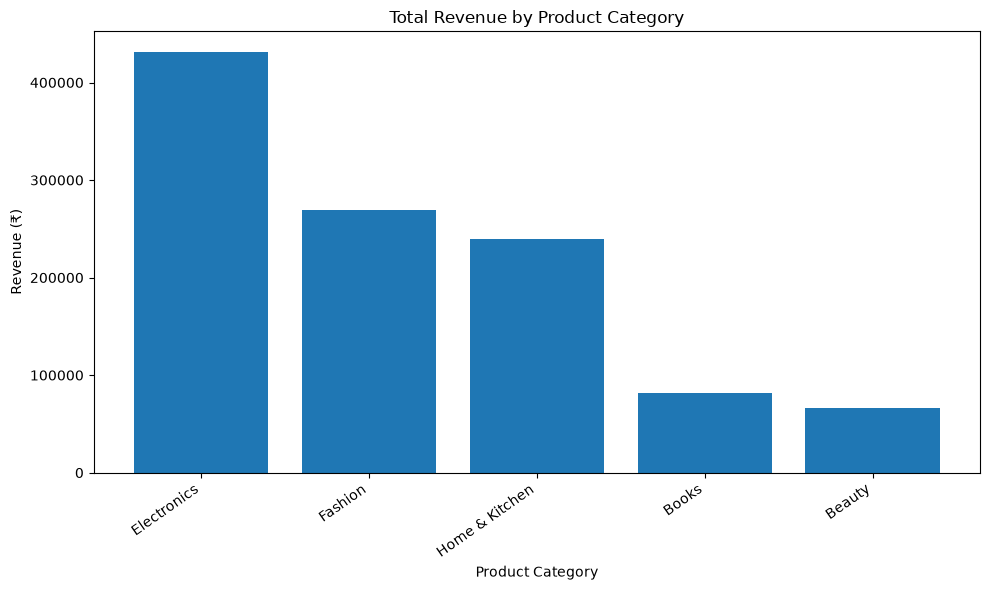

Chart saved to: C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment\outputs\charts\revenue_by_category.png
Interpretation: Electronics generates the highest revenue at ₹430,922.00.


In [20]:
# Task 3: Bar Chart - Revenue by Category

import matplotlib.pyplot as plt
from pathlib import Path

CHARTS_DIR = PROJECT_DIR / "outputs" / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

category_chart_data = category_performance.sort_values(
    "Revenue", ascending=False
)

plt.figure(figsize=(10, 6))
plt.bar(
    category_chart_data["Category"],
    category_chart_data["Revenue"]
)
plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

bar_chart_path = CHARTS_DIR / "revenue_by_category.png"
plt.savefig(bar_chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", bar_chart_path)

top_category_row = category_chart_data.iloc[0]
print(
    f"Interpretation: {top_category_row['Category']} "
    f"generates the highest revenue at "
    f"₹{top_category_row['Revenue']:,.2f}."
)

### 12.2 Monthly Revenue Trend

This line chart shows how revenue changes over time. It helps identify periods of increasing or decreasing sales and highlights the highest- and lowest-revenue months in the dataset.

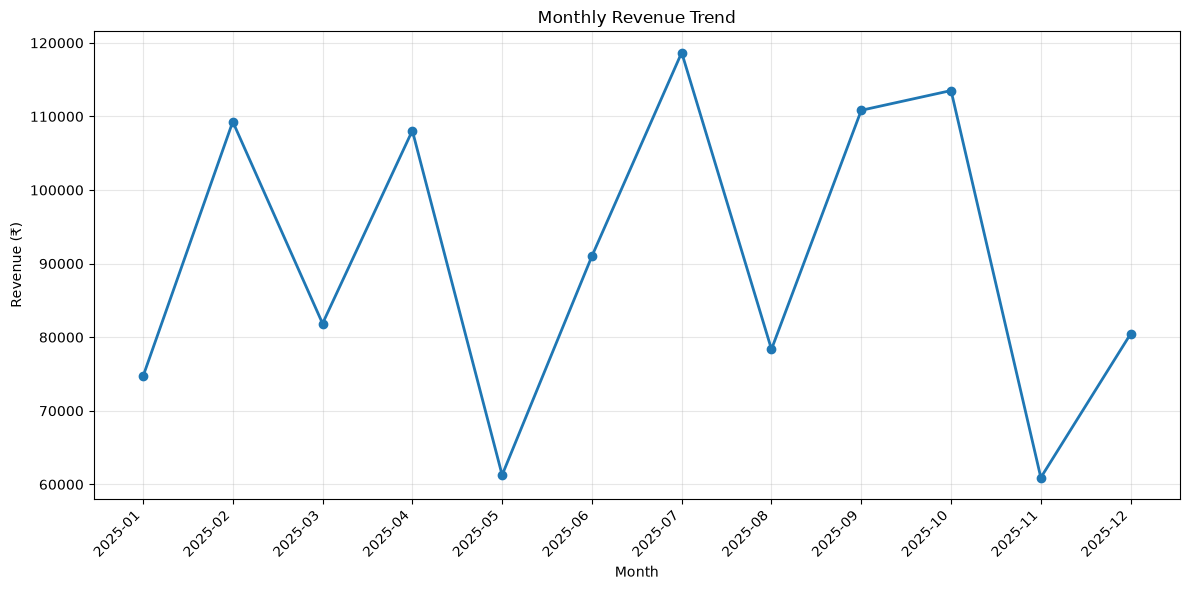

Chart saved to: C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment\outputs\charts\monthly_sales_trend.png
Interpretation: Revenue peaked in 2025-07 at ₹118,679.00.
The lowest-revenue month was 2025-11 at ₹60,922.00.


In [21]:
# Task 3: Line Chart - Monthly Revenue Trend

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()

line_chart_path = CHARTS_DIR / "monthly_sales_trend.png"
plt.savefig(line_chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", line_chart_path)

if not monthly_sales.empty:
    peak = monthly_sales.loc[monthly_sales["Revenue"].idxmax()]
    low = monthly_sales.loc[monthly_sales["Revenue"].idxmin()]

    print(
        f"Interpretation: Revenue peaked in {peak['Year-Month']} "
        f"at ₹{peak['Revenue']:,.2f}."
    )
    print(
        f"The lowest-revenue month was {low['Year-Month']} "
        f"at ₹{low['Revenue']:,.2f}."
    )

### 12.3 Payment Mode Distribution

This pie chart shows the distribution of sales records across payment modes. It helps compare the relative share of each payment method in the analyzed dataset. Missing payment modes are represented as "Unknown" where applicable.

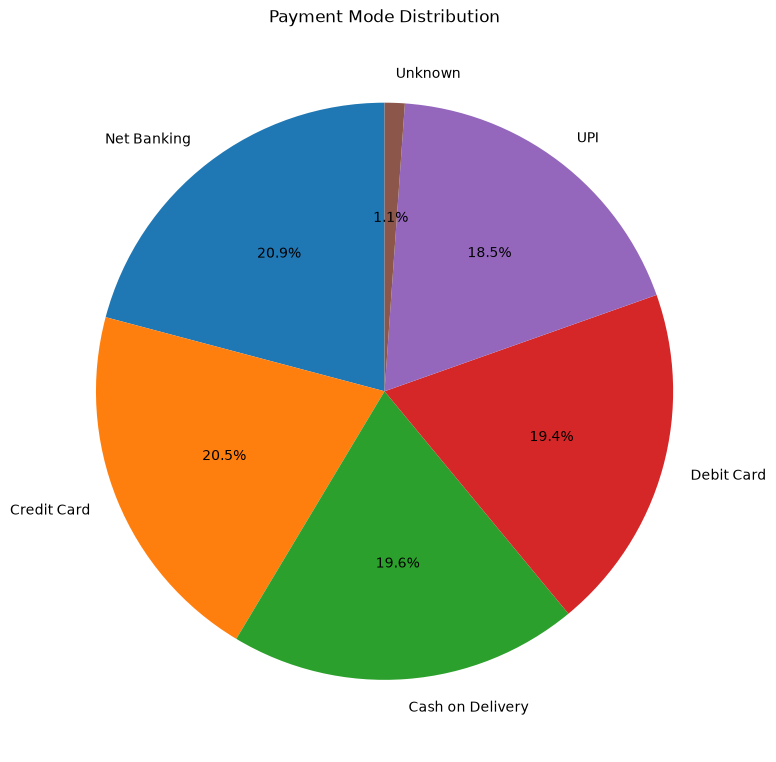

Chart saved to: C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment\outputs\charts\payment_mode_share.png

Payment mode counts:


,Records
Payment Mode,
Net Banking,130
Credit Card,128
Cash on Delivery,122
Debit Card,121
UPI,115
Unknown,7


Interpretation: The largest slice represents the most frequently recorded payment mode in the analyzed sales data.


In [22]:
# Task 3: Pie Chart - Payment Mode Distribution

if "Payment Mode" not in df_sales.columns:
    raise ValueError("Payment Mode column is missing from df_sales.")

payment_counts = (
    df_sales["Payment Mode"]
    .fillna("Unknown")
    .replace(r"^\s*$", "Unknown", regex=True)
    .value_counts()
)

if payment_counts.empty:
    print("No payment-mode data is available to plot.")
else:
    plt.figure(figsize=(8, 8))

    plt.pie(
        payment_counts.values,
        labels=payment_counts.index,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Payment Mode Distribution")
    plt.tight_layout()

    pie_chart_path = CHARTS_DIR / "payment_mode_share.png"
    plt.savefig(pie_chart_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Chart saved to:", pie_chart_path)

    print("\nPayment mode counts:")
    display(
        payment_counts.rename("Records").to_frame()
    )

    print(
        "Interpretation: The largest slice represents the most "
        "frequently recorded payment mode in the analyzed sales data."
    )

### 12.4 E-commerce Sales Dashboard Mockup

The dashboard mockup combines the main sales KPIs with category performance, monthly revenue trends, and payment-mode distribution. It provides a compact overview of business performance for a reader or decision-maker.

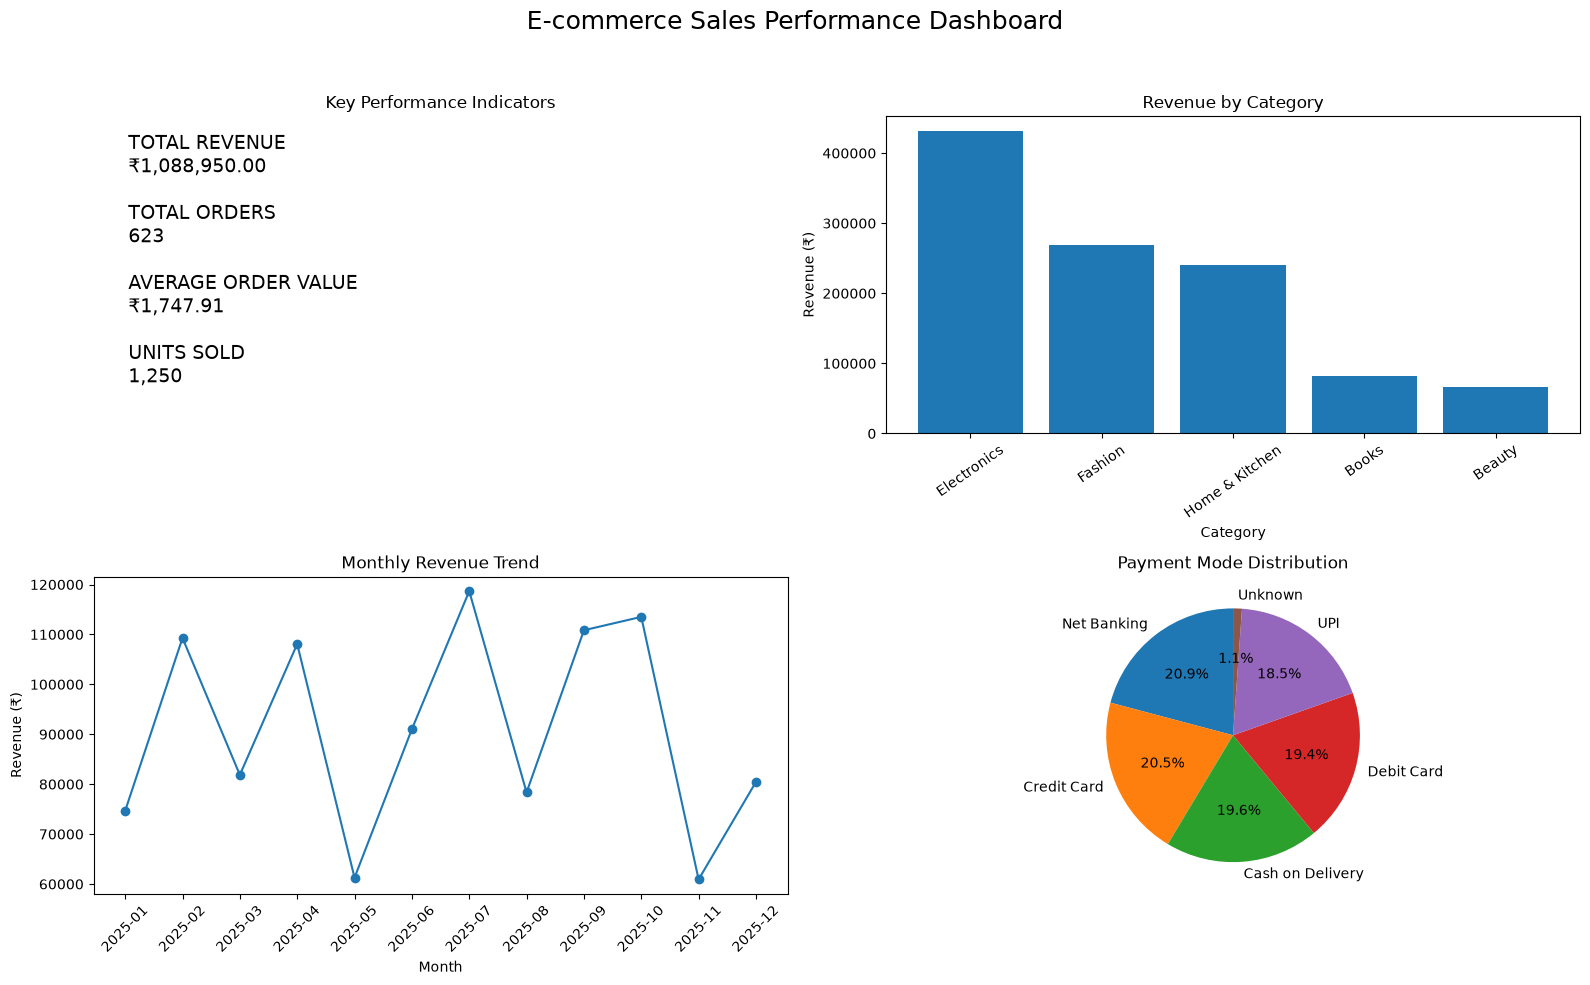

Dashboard saved to: C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment\outputs\dashboard\dashboard_mockup.png


In [23]:
# Task 3: Create the Dashboard Mockup

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("E-commerce Sales Performance Dashboard", fontsize=18)

# Panel 1: KPI summary
axes[0, 0].axis("off")

kpi_text = (
    f"TOTAL REVENUE\n₹{total_revenue:,.2f}\n\n"
    f"TOTAL ORDERS\n{total_orders:,}\n\n"
    f"AVERAGE ORDER VALUE\n₹{average_order_value:,.2f}\n\n"
    f"UNITS SOLD\n{total_units_sold:,}"
)

axes[0, 0].text(
    0.05, 0.95, kpi_text,
    transform=axes[0, 0].transAxes,
    fontsize=14,
    verticalalignment="top"
)
axes[0, 0].set_title("Key Performance Indicators")

# Panel 2: Revenue by category
axes[0, 1].bar(
    category_performance["Category"],
    category_performance["Revenue"]
)
axes[0, 1].set_title("Revenue by Category")
axes[0, 1].set_xlabel("Category")
axes[0, 1].set_ylabel("Revenue (₹)")
axes[0, 1].tick_params(axis="x", rotation=35)

# Panel 3: Monthly revenue trend
axes[1, 0].plot(
    monthly_sales["Year-Month"],
    monthly_sales["Revenue"],
    marker="o"
)
axes[1, 0].set_title("Monthly Revenue Trend")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Revenue (₹)")
axes[1, 0].tick_params(axis="x", rotation=45)

# Panel 4: Payment-mode distribution
axes[1, 1].pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1, 1].set_title("Payment Mode Distribution")

plt.tight_layout(rect=[0, 0, 1, 0.95])

dashboard_dir = PROJECT_DIR / "outputs" / "dashboard"
dashboard_dir.mkdir(parents=True, exist_ok=True)

dashboard_path = dashboard_dir / "dashboard_mockup.png"
plt.savefig(dashboard_path, dpi=300, bbox_inches="tight")
plt.show()

print("Dashboard saved to:", dashboard_path)

## 13. Key Findings and Business Recommendations

This section summarizes evidence-based observations from the sales KPIs, monthly trends, category performance, regional analysis, and customer insights.

Each finding should describe an observed result. Recommendations are presented as potential actions rather than proven outcomes. Findings are limited to the available dataset and its data-quality constraints.

In [24]:
    # Task 2: Generate Evidence-Based Business Observations

observations = []

# Finding 1: Overall performance
observations.append(
    f"1. The analyzed dataset contains {total_orders:,} distinct orders "
    f"and generates total recorded revenue of ₹{total_revenue:,.2f}."
)

# Finding 2: Average order value
observations.append(
    f"2. Average order value is ₹{average_order_value:,.2f}, "
    "calculated as total recorded revenue divided by distinct Order IDs."
)

# Finding 3: Units sold
observations.append(
    f"3. Total recorded units sold are {total_units_sold:,.0f} "
    "across the valid sales records."
)

# Finding 4: Category performance
if not category_performance.empty:
    top_cat = category_performance.iloc[0]
    observations.append(
        f"4. {top_cat['Category']} is the highest-revenue category, "
        f"with ₹{top_cat['Revenue']:,.2f} in recorded revenue."
    )

# Finding 5: Top product
if not product_revenue.empty:
    observations.append(
        f"5. {product_revenue.index[0]} is the top revenue-generating "
        f"product, contributing ₹{product_revenue.iloc[0]:,.2f}."
    )

# Finding 6: Monthly performance
if not monthly_sales.empty:
    peak_month = monthly_sales.loc[monthly_sales["Revenue"].idxmax()]
    observations.append(
        f"6. {peak_month['Year-Month']} is the highest-revenue month, "
        f"with ₹{peak_month['Revenue']:,.2f}."
    )

# Finding 7: Regional performance
if "regional_performance" in globals() and not regional_performance.empty:
    region_col = regional_performance.columns[0]
    top_region = regional_performance.iloc[0]
    observations.append(
        f"7. {top_region[region_col]} is the highest-revenue region "
        f"among the regions represented, with "
        f"₹{top_region['Revenue']:,.2f}."
    )

# Finding 8: Payment-mode distribution
if not payment_counts.empty:
    observations.append(
        f"8. {payment_counts.index[0]} is the most frequently recorded "
        f"payment mode, appearing in {payment_counts.iloc[0]:,} sales records."
    )

for observation in observations:
    print(observation)

1. The analyzed dataset contains 623 distinct orders and generates total recorded revenue of ₹1,088,950.00.
2. Average order value is ₹1,747.91, calculated as total recorded revenue divided by distinct Order IDs.
3. Total recorded units sold are 1,250 across the valid sales records.
4. Electronics is the highest-revenue category, with ₹430,922.00 in recorded revenue.
5. Smart Watch is the top revenue-generating product, contributing ₹222,411.00.
6. 2025-07 is the highest-revenue month, with ₹118,679.00.
7. Jaipur is the highest-revenue region among the regions represented, with ₹165,868.00.
8. Net Banking is the most frequently recorded payment mode, appearing in 130 sales records.


### 13.1 Business Recommendations

1. **Prioritize high-performing categories:** Review the products, pricing, and availability within the categories generating the most revenue.
2. **Review top revenue-generating products:** Monitor stock availability and product performance before making inventory decisions.
3. **Investigate monthly fluctuations:** Compare high- and low-revenue months with promotions, demand, and order volumes before attributing a cause.
4. **Evaluate regional differences:** Investigate local demand, product mix, and delivery performance in high- and low-revenue regions.
5. **Encourage repeat purchases:** Consider retention initiatives after reviewing repeat-customer contribution and customer purchasing patterns.
6. **Improve data quality:** Continue monitoring missing customer IDs, payment modes, locations, and invalid numeric or date values.
7. **Use payment-mode results carefully:** Review payment preferences when planning checkout improvements, while distinguishing record share from revenue share.

These recommendations are proposed actions based on descriptive analysis. Their effectiveness would need to be tested against subsequent business results.

## 14. Limitations and Assumptions

### Limitations

1. **Data representativeness:** The analysis describes only the records available in the supplied dataset and may not represent the entire business.
2. **Missing information:** Missing customer identifiers, payment modes, and locations can limit customer-level and categorical analysis.
3. **Duplicate handling:** Fully identical rows were removed from the working copy. Repeated Order IDs were not automatically removed because they may represent valid records.
4. **Invalid records:** Records that fail the sales-analysis validation rules are excluded from the analytical dataset, but remain available in the cleaned working dataset for traceability.
5. **Causality:** The analysis identifies patterns and associations but cannot establish why revenue or customer behavior changes.
6. **Seasonality:** Seasonal conclusions require sufficient data across relevant periods. A short observation window is not enough to establish recurring seasonal patterns.
7. **Customer identification:** Customer-level insights depend on the quality and completeness of Customer ID values.

### Assumptions

1. Order IDs are used to count distinct orders.
2. Total Amount is used as the recorded transaction value for revenue calculations.
3. Average order value is calculated as total recorded revenue divided by distinct Order IDs in the valid sales-analysis dataset.
4. The top-selling category is defined by total units sold.
5. The top revenue-generating product is defined by summed Total Amount.
6. Missing categorical values labelled "Unknown" remain separate from known categories.
7. Recommendations are proposed actions that require further evaluation before implementation.

These assumptions should be revisited if the dataset documentation provides different business definitions.

In [25]:
# Task 1: Save Cleaning Decision Documentation

REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

cleaning_log_path = REPORTS_DIR / "cleaning_decisions.csv"
cleaning_decisions.to_csv(cleaning_log_path, index=False)

print("Cleaning decision log saved to:", cleaning_log_path)
display(cleaning_decisions)

Cleaning decision log saved to: C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment\reports\cleaning_decisions.csv


,Issue,Investigation,Decision,Justification
0,Missing values,Review missing counts and percentages by column,Pending review of missing-value report,Choose handling based on column meaning and an...
1,Exact duplicate rows,Check fully identical rows,Remove confirmed exact duplicates from the wor...,Prevent duplicate records from inflating analysis
2,Repeated Order IDs,Inspect records sharing the same Order ID,Retain unless evidence confirms an accidental ...,Repeated IDs may represent valid order line items
3,Quantity,"Check missing, non-numeric, zero, and negative...",Pending validation results,Invalid quantities affect units sold
4,Unit Price,"Check missing, non-numeric, zero, and negative...",Pending validation results,Invalid prices affect revenue
5,Order Date,Check missing and unparseable dates,Convert valid dates to datetime; investigate i...,Dates are required for time-based analysis
6,Delivery Status and Category,Review distinct text values,Standardize text formatting while preserving m...,Consistent labels improve analysis


## 15. Project Structure and Deliverable Verification

This section checks the required project folders and output files before final reporting. The verification covers the raw and cleaned datasets, analysis notebook, visualizations, dashboard mockup, cleaning documentation, and report directory.

Missing files will be identified for completion before submission.

In [26]:
# Final Project Verification

required_paths = {
    "Raw dataset": PROJECT_DIR / "data" / "raw" / "ecommerce_sales_raw.csv",
    "Cleaned dataset": PROJECT_DIR / "data" / "cleaned" / "ecommerce_sales_cleaned.csv",
    "Analysis notebook": PROJECT_DIR / "notebooks" / "week1_analysis.ipynb",
    "Revenue by category chart": PROJECT_DIR / "outputs" / "charts" / "revenue_by_category.png",
    "Monthly sales trend chart": PROJECT_DIR / "outputs" / "charts" / "monthly_sales_trend.png",
    "Payment mode chart": PROJECT_DIR / "outputs" / "charts" / "payment_mode_share.png",
    "Dashboard mockup": PROJECT_DIR / "outputs" / "dashboard" / "dashboard_mockup.png",
    "Cleaning decisions log": PROJECT_DIR / "reports" / "cleaning_decisions.csv",
    "README": PROJECT_DIR / "README.md",
    "Requirements": PROJECT_DIR / "requirements.txt",
}

verification_results = []

for deliverable, path in required_paths.items():
    verification_results.append({
        "Deliverable": deliverable,
        "Status": "PRESENT" if path.exists() else "MISSING",
        "Path": str(path)
    })

verification_df = pd.DataFrame(verification_results)
display(verification_df)

missing_files = verification_df.loc[
    verification_df["Status"] == "MISSING", "Deliverable"
].tolist()

print("\nVerification summary")
print("-" * 50)
print("Required items checked:", len(required_paths))
print("Items present:", int((verification_df["Status"] == "PRESENT").sum()))
print("Items missing:", len(missing_files))

if missing_files:
    print("\nComplete these items before final submission:")
    for item in missing_files:
        print("-", item)
else:
    print("All checked files are present.")

,Deliverable,Status,Path
0,Raw dataset,PRESENT,C:\Users\rishi\OneDrive\Desktop\data-science-w...
1,Cleaned dataset,PRESENT,C:\Users\rishi\OneDrive\Desktop\data-science-w...
2,Analysis notebook,PRESENT,C:\Users\rishi\OneDrive\Desktop\data-science-w...
3,Revenue by category chart,PRESENT,C:\Users\rishi\OneDrive\Desktop\data-science-w...
4,Monthly sales trend chart,PRESENT,C:\Users\rishi\OneDrive\Desktop\data-science-w...
5,Payment mode chart,PRESENT,C:\Users\rishi\OneDrive\Desktop\data-science-w...
6,Dashboard mockup,PRESENT,C:\Users\rishi\OneDrive\Desktop\data-science-w...
7,Cleaning decisions log,PRESENT,C:\Users\rishi\OneDrive\Desktop\data-science-w...
8,README,PRESENT,C:\Users\rishi\OneDrive\Desktop\data-science-w...
9,Requirements,PRESENT,C:\Users\rishi\OneDrive\Desktop\data-science-w...



Verification summary
--------------------------------------------------
Required items checked: 10
Items present: 10
Items missing: 0
All checked files are present.


## 16. Final Project Report

This section generates a consolidated PDF report using the results produced by the notebook. It summarizes the data-cleaning process, business KPIs, sales trends, category and regional performance, customer insights, visualizations, findings, recommendations, and limitations.

In [27]:
%pip install reportlab

Note: you may need to restart the kernel to use updated packages.


In [28]:

# ============================================================
# FINAL PDF REPORT GENERATION — CORRECTED VERSION
# WeIntern Pvt Ltd | Week 1 Data Science Internship
# ============================================================

from pathlib import Path
from datetime import datetime
import re
import pandas as pd
import numpy as np

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch
from reportlab.lib.utils import ImageReader
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image as RLImage, PageBreak, KeepTogether
)
from xml.sax.saxutils import escape


# ============================================================
# 1. VALIDATE REQUIRED VARIABLES
# ============================================================

required_variables = [
    "PROJECT_DIR",
    "df_raw",
    "df_clean",
    "df_sales",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run the data loading, cleaning, and analysis cells first."
    )


# ============================================================
# 2. PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(PROJECT_DIR)

REPORTS_DIR = PROJECT_DIR / "reports"
CHARTS_DIR = PROJECT_DIR / "outputs" / "charts"
DASHBOARD_DIR = PROJECT_DIR / "outputs" / "dashboard"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

report_pdf_path = REPORTS_DIR / "final_report.pdf"

# If the existing PDF is open or locked, use a timestamped filename.
if report_pdf_path.exists():
    try:
        with open(report_pdf_path, "ab"):
            pass
    except PermissionError:
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        report_pdf_path = (
            REPORTS_DIR / f"final_report_{timestamp}.pdf"
        )


# ============================================================
# 3. HELPER FUNCTIONS FOR DATA AND FORMATTING
# ============================================================

def is_missing(value):
    try:
        result = pd.isna(value)
        return bool(result) if np.isscalar(result) else False
    except (TypeError, ValueError):
        return False


def clean_string(value):
    if is_missing(value):
        return "Not available"
    return str(value)


def number_value(value):
    try:
        result = pd.to_numeric(value, errors="coerce")
        return float(result) if pd.notna(result) else np.nan
    except (TypeError, ValueError):
        return np.nan


def format_number(value, decimals=2):
    number = number_value(value)
    if pd.isna(number):
        return clean_string(value)
    return f"{number:,.{decimals}f}"


def format_inr(value):
    number = number_value(value)
    if pd.isna(number):
        return "Not available"
    return f"INR {number:,.2f}"


def find_column(dataframe, candidates):
    """Find a column by case-insensitive name or known alias."""
    if not isinstance(dataframe, pd.DataFrame):
        return None

    lookup = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:
        key = candidate.strip().lower()
        if key in lookup:
            return lookup[key]

    return None


def get_numeric_series(dataframe, column):
    if column is None or column not in dataframe.columns:
        return pd.Series(dtype=float)

    return pd.to_numeric(dataframe[column], errors="coerce")


def safe_sum(series):
    numeric = pd.to_numeric(series, errors="coerce")
    return float(numeric.sum()) if numeric.notna().any() else 0.0


def safe_divide(numerator, denominator):
    if denominator is None or denominator == 0:
        return np.nan
    return numerator / denominator


# Identify commonly used columns.
revenue_col = find_column(
    df_sales,
    ["Total Amount", "Total_Amount", "Revenue", "Sales", "Amount"]
)

order_col = find_column(
    df_sales,
    ["Order ID", "Order_ID", "OrderID", "Order Number"]
)

quantity_col = find_column(
    df_sales,
    ["Quantity", "Units Sold", "Units_Sold", "Qty"]
)

date_col = find_column(
    df_sales,
    ["Order Date", "Order_Date", "Date", "Purchase Date"]
)

category_col = find_column(
    df_sales,
    ["Category", "Product Category", "Product_Category"]
)

product_col = find_column(
    df_sales,
    ["Product", "Product Name", "Product_Name", "Item"]
)

customer_col = find_column(
    df_sales,
    ["Customer ID", "Customer_ID", "CustomerID"]
)

payment_col = find_column(
    df_sales,
    ["Payment Mode", "Payment_Mode", "Payment Method", "Payment_Method"]
)

# Region may be recorded under several possible column names.
region_col = find_column(
    df_sales,
    [
        "Region", "City", "State", "Location",
        "Customer Region", "Customer_Region",
        "Shipping Region", "Shipping_Region"
    ]
)


# ============================================================
# 4. CREATE REPORT STYLES
# ============================================================

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="FinalReportTitle",
    parent=styles["Title"],
    fontName="Helvetica-Bold",
    fontSize=21,
    leading=26,
    alignment=TA_CENTER,
    spaceAfter=12
))

styles.add(ParagraphStyle(
    name="FinalReportSubtitle",
    parent=styles["Normal"],
    fontSize=10,
    leading=15,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#555555"),
    spaceAfter=6
))

styles.add(ParagraphStyle(
    name="FinalSectionHeading",
    parent=styles["Heading2"],
    fontName="Helvetica-Bold",
    fontSize=13,
    leading=17,
    textColor=colors.HexColor("#1F4E79"),
    spaceBefore=10,
    spaceAfter=7,
    keepWithNext=True
))

styles.add(ParagraphStyle(
    name="FinalChartHeading",
    parent=styles["Heading3"],
    fontName="Helvetica-Bold",
    fontSize=10,
    leading=13,
    spaceBefore=5,
    spaceAfter=5,
    keepWithNext=True
))

styles.add(ParagraphStyle(
    name="FinalReportBody",
    parent=styles["BodyText"],
    fontName="Helvetica",
    fontSize=9,
    leading=13,
    spaceAfter=6
))

styles.add(ParagraphStyle(
    name="FinalReportNote",
    parent=styles["BodyText"],
    fontName="Helvetica-Oblique",
    fontSize=8,
    leading=11,
    textColor=colors.HexColor("#555555"),
    spaceAfter=5
))


# ============================================================
# 5. REPORT CONTENT HELPERS
# ============================================================

story = []
charts_included = 0


def add_paragraph(text, style="FinalReportBody"):
    story.append(
        Paragraph(escape(clean_string(text)), styles[style])
    )


def add_heading(text):
    story.append(
        Paragraph(
            escape(str(text)),
            styles["FinalSectionHeading"]
        )
    )


def add_bullet(text):
    story.append(
        Paragraph(
            "&bull;&nbsp;" + escape(clean_string(text)),
            styles["FinalReportBody"]
        )
    )


def format_table_value(value, column_name=""):
    """Format currency, averages, percentages, and ordinary numbers."""

    col = str(column_name).lower()

    if is_missing(value):
        return "Not available"

    # Monetary and average-value columns.
    if any(term in col for term in [
        "revenue", "amount", "sales", "average_order_value",
        "average order value", "aov", "price", "spend"
    ]):
        number = number_value(value)
        if pd.notna(number):
            return f"{number:,.2f}"

    # Percentage columns.
    if "percent" in col or "percentage" in col or "share" in col:
        number = number_value(value)
        if pd.notna(number):
            return f"{number:,.2f}"

    # Ordinary numeric values.
    if isinstance(value, (int, np.integer)):
        return f"{value:,}"

    if isinstance(value, (float, np.floating)):
        if np.isfinite(value):
            if float(value).is_integer():
                return f"{int(value):,}"
            return f"{value:,.2f}"

    return str(value)


def add_table(rows, font_size=8, first_column_names=None):
    if not rows:
        add_paragraph("No data available.")
        return

    formatted_rows = []

    headers = [str(value) for value in rows[0]]

    for row_index, row in enumerate(rows):
        formatted_row = []

        for col_index, value in enumerate(row):
            column_name = (
                headers[col_index]
                if row_index > 0 and col_index < len(headers)
                else ""
            )

            if row_index == 0:
                display_value = clean_string(value)
            else:
                display_value = format_table_value(
                    value, column_name
                )

            cell_style = ParagraphStyle(
                name=f"FinalCell_{len(formatted_rows)}_{col_index}",
                fontName=(
                    "Helvetica-Bold" if row_index == 0
                    else "Helvetica"
                ),
                fontSize=font_size,
                leading=font_size + 2
            )

            formatted_row.append(
                Paragraph(
                    escape(display_value),
                    cell_style
                )
            )

        formatted_rows.append(formatted_row)

    table = Table(
        formatted_rows,
        repeatRows=1,
        hAlign="LEFT"
    )

    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0),
         colors.HexColor("#1F4E79")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("GRID", (0, 0), (-1, -1), 0.4,
         colors.HexColor("#CCCCCC")),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("LEFTPADDING", (0, 0), (-1, -1), 5),
        ("RIGHTPADDING", (0, 0), (-1, -1), 5),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#F3F6F9")])
    ]))

    story.append(table)
    story.append(Spacer(1, 8))


def add_dataframe(dataframe, max_rows=20):
    if not isinstance(dataframe, pd.DataFrame) or dataframe.empty:
        add_paragraph("No results available for this section.")
        return

    display_df = dataframe.head(max_rows).copy()
    rows = [list(display_df.columns)]

    for row in display_df.itertuples(index=False, name=None):
        rows.append(list(row))

    add_table(rows, font_size=7)

    if len(dataframe) > max_rows:
        add_paragraph(
            f"Showing {max_rows} of {len(dataframe)} rows.",
            "FinalReportNote"
        )


# ============================================================
# 6. CHART INSERTION
# ============================================================

def add_chart_section(title, image_path, explanation=None):
    global charts_included

    image_path = Path(image_path)

    if not image_path.is_file():
        print(f"CHART MISSING: {image_path}")
        return False

    try:
        image_reader = ImageReader(str(image_path))
        image_width, image_height = image_reader.getSize()

        if image_width <= 0 or image_height <= 0:
            raise ValueError("Invalid image dimensions.")

        chart = RLImage(str(image_path))

        max_width = 6.2 * inch
        max_height = 4.2 * inch

        scale = min(
            max_width / image_width,
            max_height / image_height
        )

        chart.drawWidth = image_width * scale
        chart.drawHeight = image_height * scale

        group = [
            Paragraph(
                escape(str(title)),
                styles["FinalChartHeading"]
            ),
            Spacer(1, 4),
            chart
        ]

        if explanation:
            group.extend([
                Spacer(1, 5),
                Paragraph(
                    escape(str(explanation)),
                    styles["FinalReportNote"]
                )
            ])

        story.append(KeepTogether(group))
        story.append(Spacer(1, 10))

        charts_included += 1
        print(f"CHART ADDED: {title}")
        return True

    except Exception as exc:
        print(
            f"CHART INSERTION FAILED: {title} | "
            f"{type(exc).__name__}: {exc}"
        )
        return False


def add_page_number(canvas, doc):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.HexColor("#555555"))
    canvas.drawCentredString(
        A4[0] / 2,
        0.35 * inch,
        f"Page {doc.page}"
    )
    canvas.restoreState()


# ============================================================
# 7. PREPARE CORE METRICS FROM THE CURRENT DATA
# ============================================================

raw_rows = len(df_raw)
clean_rows = len(df_clean)
analysis_rows = len(df_sales)

duplicate_count = int(df_raw.duplicated().sum())
missing_before = int(df_raw.isna().sum().sum())
missing_after = int(df_clean.isna().sum().sum())

revenue_series = (
    get_numeric_series(df_sales, revenue_col)
    if revenue_col else pd.Series(dtype=float)
)

quantity_series = (
    get_numeric_series(df_sales, quantity_col)
    if quantity_col else pd.Series(dtype=float)
)

total_revenue = (
    float(revenue_series.fillna(0).sum())
    if revenue_col else None
)

units_sold = (
    float(quantity_series.fillna(0).sum())
    if quantity_col else None
)

total_orders = (
    int(df_sales[order_col].nunique())
    if order_col else None
)

average_order_value = (
    safe_divide(total_revenue, total_orders)
    if total_revenue is not None and total_orders is not None
    else None
)

print("Detected columns:")
print(f"Revenue: {revenue_col}")
print(f"Order ID: {order_col}")
print(f"Quantity: {quantity_col}")
print(f"Date: {date_col}")
print(f"Category: {category_col}")
print(f"Product: {product_col}")
print(f"Customer ID: {customer_col}")
print(f"Payment mode: {payment_col}")
print(f"Region/city: {region_col}")


# ============================================================
# 8. TITLE AND OVERVIEW
# ============================================================

story.append(Spacer(1, 0.6 * inch))

story.append(Paragraph(
    "DATA SCIENCE INTERNSHIP",
    styles["FinalReportTitle"]
))

story.append(Paragraph(
    "Week 1 Assignment: E-commerce Sales Analysis",
    styles["FinalReportSubtitle"]
))

story.append(Spacer(1, 0.2 * inch))

story.append(Paragraph(
    "Prepared by: Rishi Kuber",
    styles["FinalReportSubtitle"]
))

story.append(Paragraph(
    "Organization: WeIntern Pvt Ltd",
    styles["FinalReportSubtitle"]
))

story.append(Paragraph(
    "Generated: " + datetime.now().strftime("%d %B %Y"),
    styles["FinalReportSubtitle"]
))

story.append(Spacer(1, 0.25 * inch))

add_paragraph(
    "This report documents the data preparation, validation, "
    "key performance indicators, sales trends, category and "
    "regional performance, customer insights, and visualizations "
    "for the Week 1 Data Science Internship assignment."
)

add_paragraph(
    "Dataset note: The project uses a synthetic educational "
    "e-commerce dataset. Its results do not represent actual "
    "company performance."
)

story.append(PageBreak())


# ============================================================
# 9. DATASET OVERVIEW
# ============================================================

add_heading("1. Dataset Overview")

add_paragraph(
    "The analysis examines sales records to summarize revenue, "
    "orders, products, regions, customers, and payment preferences."
)

add_table([
    ["Metric", "Value"],
    ["Raw rows", raw_rows],
    ["Raw columns", len(df_raw.columns)],
    ["Cleaned rows", clean_rows],
    ["Cleaned columns", len(df_clean.columns)],
    ["Rows used in sales analysis", analysis_rows]
])


# ============================================================
# 10. CLEANING AND VALIDATION
# ============================================================

add_heading("2. Data Cleaning and Validation")

add_paragraph(
    "The raw and cleaned datasets were reviewed for missing "
    "values, duplicate rows, inconsistent formats, and invalid "
    "values that could affect the analysis."
)

add_table([
    ["Check", "Result"],
    ["Exact duplicate rows in raw data", duplicate_count],
    ["Missing cells before cleaning", missing_before],
    ["Missing cells after cleaning", missing_after],
    ["Rows before cleaning", raw_rows],
    ["Rows after cleaning", clean_rows]
])

if (REPORTS_DIR / "cleaning_decisions.csv").exists():
    add_paragraph(
        "Cleaning decision log: reports/cleaning_decisions.csv"
    )
elif (REPORTS_DIR / "cleaning_decisions.md").exists():
    add_paragraph(
        "Cleaning decision log: reports/cleaning_decisions.md"
    )

add_paragraph(
    "Refer to the notebook's cleaning cells and decision log "
    "for the specific rules applied to the dataset."
)


# ============================================================
# 11. KPI SUMMARY
# ============================================================

add_heading("3. Key Performance Indicators")

kpi_summary = globals().get("kpi_summary", pd.DataFrame())

if isinstance(kpi_summary, pd.DataFrame) and not kpi_summary.empty:
    add_dataframe(kpi_summary)
elif isinstance(kpi_summary, dict) and kpi_summary:
    add_table(
        [["KPI", "Value"]]
        + [[key, value] for key, value in kpi_summary.items()]
    )
else:
    add_paragraph(
        "The KPI summary table was unavailable. "
        "The core metrics below are calculated directly from df_sales."
    )

core_kpi_rows = [["KPI", "Value"]]

if total_revenue is not None:
    core_kpi_rows.append([
        "Total analysis revenue",
        format_inr(total_revenue)
    ])

if total_orders is not None:
    core_kpi_rows.append([
        "Distinct orders",
        f"{total_orders:,}"
    ])

if average_order_value is not None:
    core_kpi_rows.append([
        "Average order value",
        format_inr(average_order_value)
    ])

if units_sold is not None:
    core_kpi_rows.append([
        "Units sold",
        format_number(units_sold, 0)
    ])

if len(core_kpi_rows) > 1:
    add_table(core_kpi_rows)


# ============================================================
# 12. MONTHLY SALES TREND
# ============================================================

add_heading("4. Monthly Sales Trend")

add_paragraph(
    "Monthly sales analysis helps identify periods of higher "
    "and lower revenue. The following table uses the existing "
    "monthly analysis output when available."
)

monthly_sales = globals().get("monthly_sales", pd.DataFrame())

if isinstance(monthly_sales, pd.DataFrame) and not monthly_sales.empty:
    add_dataframe(monthly_sales, max_rows=24)
elif date_col and revenue_col:
    monthly_df = df_sales[[date_col, revenue_col]].copy()
    monthly_df[date_col] = pd.to_datetime(
        monthly_df[date_col], errors="coerce"
    )
    monthly_df[revenue_col] = pd.to_numeric(
        monthly_df[revenue_col], errors="coerce"
    )

    monthly_df = monthly_df.dropna(subset=[date_col])

    monthly_df["Year-Month"] = (
        monthly_df[date_col].dt.to_period("M").astype(str)
    )

    monthly_summary = (
        monthly_df.groupby("Year-Month")
        .agg(Revenue=(revenue_col, "sum"))
        .reset_index()
    )

    add_dataframe(monthly_summary, max_rows=24)
else:
    add_paragraph(
        "Monthly analysis could not be calculated because the "
        "required date or revenue column is missing."
    )


# ============================================================
# 13. CATEGORY PERFORMANCE
# ============================================================

add_heading("5. Product Category Performance")

add_paragraph(
    "Category analysis compares revenue and sales volume across "
    "product categories. The highest-revenue category may differ "
    "from the category with the most units sold."
)

category_performance = globals().get(
    "category_performance", pd.DataFrame()
)

if (
    isinstance(category_performance, pd.DataFrame)
    and not category_performance.empty
):
    add_dataframe(category_performance)
elif category_col and revenue_col:
    cat_df = df_sales.copy()
    cat_df[revenue_col] = pd.to_numeric(
        cat_df[revenue_col], errors="coerce"
    )

    aggregation = {revenue_col: "sum"}

    if quantity_col:
        cat_df[quantity_col] = pd.to_numeric(
            cat_df[quantity_col], errors="coerce"
        )
        aggregation[quantity_col] = "sum"

    cat_summary = (
        cat_df.groupby(category_col, dropna=False)
        .agg(aggregation)
        .reset_index()
    )

    add_dataframe(cat_summary)
else:
    add_paragraph(
        "Category analysis requires category and revenue columns."
    )


# ============================================================
# 14. REGIONAL PERFORMANCE — CORRECTED
# ============================================================

add_heading("6. Regional Performance")

if region_col and revenue_col:
    regional_df = df_sales[[region_col, revenue_col]].copy()

    regional_df[revenue_col] = pd.to_numeric(
        regional_df[revenue_col], errors="coerce"
    )

    regional_df = regional_df.dropna(subset=[region_col])

    regional_summary = (
        regional_df.groupby(region_col, dropna=False)
        .agg(
            Revenue=(revenue_col, "sum"),
            Sales_Rows=(revenue_col, "size")
        )
        .reset_index()
        .sort_values("Revenue", ascending=False)
    )

    if not regional_summary.empty:
        add_dataframe(regional_summary)

        top_region = regional_summary.iloc[0]
        add_paragraph(
            f"The highest-revenue {region_col.lower()} in the "
            f"available data is {top_region[region_col]}, with "
            f"{format_inr(top_region['Revenue'])} in revenue."
        )
    else:
        add_paragraph(
            f"The column '{region_col}' exists, but no usable "
            "regional records were available."
        )

elif region_col and not revenue_col:
    add_paragraph(
        f"The column '{region_col}' was detected, but a revenue "
        "column could not be identified. Regional revenue was "
        "not calculated."
    )

elif not region_col:
    add_paragraph(
        "Regional analysis was not calculated because df_sales "
        "does not contain a recognized region, city, state, or "
        "location column. No regional leader is claimed in this report."
    )

else:
    add_paragraph(
        "Regional analysis could not be calculated from the "
        "available sales-analysis columns."
    )


# ============================================================
# 15. CUSTOMER INSIGHTS
# ============================================================

add_heading("7. Customer Insights")

customer_summary = pd.DataFrame()

if customer_col and revenue_col:
    customer_df = df_sales.copy()

    customer_df[customer_col] = (
        customer_df[customer_col]
        .astype("string")
        .str.strip()
    )

    invalid_customer_mask = (
        customer_df[customer_col].isna()
        | customer_df[customer_col].eq("")
        | customer_df[customer_col].str.lower().isin(
            ["unknown", "nan", "none"]
        )
    ).fillna(True)

    customer_df = customer_df.loc[
        ~invalid_customer_mask
    ].copy()

    customer_df[revenue_col] = pd.to_numeric(
        customer_df[revenue_col], errors="coerce"
    ).fillna(0)

    customer_summary = (
        customer_df.groupby(customer_col)
        .agg(
            Customer_Revenue=(revenue_col, "sum"),
            Purchase_Rows=(customer_col, "size")
        )
        .reset_index()
        .sort_values("Customer_Revenue", ascending=False)
    )

    add_paragraph("Top identifiable customers by revenue:")
    add_dataframe(customer_summary.head(10))

    repeat_customers = int(
        (customer_summary["Purchase_Rows"] > 1).sum()
    )

    add_paragraph(
        f"Customers with more than one sales-analysis row: "
        f"{repeat_customers:,}."
    )

else:
    add_paragraph(
        "Customer analysis requires identifiable customer ID "
        "and revenue columns."
    )


# ============================================================
# 16. CUSTOMER REVENUE RECONCILIATION
# ============================================================

add_heading("8. Customer Revenue Reconciliation")

if customer_col and revenue_col and total_revenue is not None:
    reconciliation_df = df_sales.copy()

    reconciliation_df[revenue_col] = pd.to_numeric(
        reconciliation_df[revenue_col], errors="coerce"
    ).fillna(0)

    customer_ids = (
        reconciliation_df[customer_col]
        .astype("string")
        .str.strip()
    )

    unidentified_mask = (
        customer_ids.isna()
        | customer_ids.eq("")
        | customer_ids.str.lower().isin(
            ["unknown", "nan", "none"]
        )
    ).fillna(True)

    identified_revenue = float(
        reconciliation_df.loc[
            ~unidentified_mask, revenue_col
        ].sum()
    )

    unidentified_revenue = float(
        reconciliation_df.loc[
            unidentified_mask, revenue_col
        ].sum()
    )

    reconciled_revenue = (
        identified_revenue + unidentified_revenue
    )

    add_table([
        ["Revenue component", "Amount"],
        ["Total analysis revenue", format_inr(total_revenue)],
        ["Revenue with identifiable customer IDs",
         format_inr(identified_revenue)],
        ["Revenue without identifiable customer IDs",
         format_inr(unidentified_revenue)],
        ["Reconciled revenue", format_inr(reconciled_revenue)]
    ])

    if np.isclose(
        reconciled_revenue,
        total_revenue,
        atol=0.01
    ):
        add_paragraph(
            "Reconciliation check passed: identified and "
            "unidentified customer revenue sum to total revenue."
        )
    else:
        add_paragraph(
            "Reconciliation check failed. Review the revenue "
            "and customer ID filtering rules."
        )

else:
    add_paragraph(
        "Customer revenue reconciliation requires customer ID "
        "and revenue columns."
    )


# ============================================================
# 17. VISUALIZATIONS — ALL FOUR CHARTS
# ============================================================

add_heading("9. Visualizations")

chart_files = [
    (
        "Revenue by Category",
        CHARTS_DIR / "revenue_by_category.png"
    ),
    (
        "Monthly Sales Trend",
        CHARTS_DIR / "monthly_sales_trend.png"
    ),
    (
        "Payment Mode Share",
        CHARTS_DIR / "payment_mode_share.png"
    ),
    (
        "Dashboard Overview",
        DASHBOARD_DIR / "dashboard_mockup.png"
    )
]

charts_included = 0

for title, image_path in chart_files:
    add_chart_section(title, image_path)

print(f"Charts inserted into report: {charts_included} of 4")


# ============================================================
# 18. CHART INTERPRETATIONS — DATA-DRIVEN
# ============================================================

add_heading("10. Chart Interpretations")

# Category chart interpretation.
if category_col and revenue_col:
    cat_df = df_sales[[category_col, revenue_col]].copy()
    cat_df[revenue_col] = pd.to_numeric(
        cat_df[revenue_col], errors="coerce"
    )
    cat_df = cat_df.dropna(subset=[category_col, revenue_col])

    if not cat_df.empty:
        cat_summary = (
            cat_df.groupby(category_col)[revenue_col]
            .sum()
            .sort_values(ascending=False)
        )

        add_paragraph("Revenue by Category", "FinalChartHeading")
        add_paragraph(
            f"{cat_summary.index[0]} has the highest recorded "
            f"category revenue at {format_inr(cat_summary.iloc[0])}."
        )

        if len(cat_summary) > 1:
            add_paragraph(
                f"{cat_summary.index[-1]} has the lowest recorded "
                f"category revenue at {format_inr(cat_summary.iloc[-1])}."
            )
    else:
        add_paragraph(
            "Category interpretation is unavailable because no "
            "valid category revenue records were found."
        )
else:
    add_paragraph(
        "Category interpretation requires category and revenue columns."
    )

# Monthly chart interpretation.
if date_col and revenue_col:
    trend_df = df_sales[[date_col, revenue_col]].copy()
    trend_df[date_col] = pd.to_datetime(
        trend_df[date_col], errors="coerce"
    )
    trend_df[revenue_col] = pd.to_numeric(
        trend_df[revenue_col], errors="coerce"
    )

    trend_df = trend_df.dropna(subset=[date_col, revenue_col])

    if not trend_df.empty:
        trend_df["Year-Month"] = (
            trend_df[date_col].dt.to_period("M").astype(str)
        )

        monthly_summary = (
            trend_df.groupby("Year-Month")[revenue_col]
            .sum()
            .sort_index()
        )

        peak_month = monthly_summary.idxmax()
        low_month = monthly_summary.idxmin()

        add_paragraph("Monthly Sales Trend", "FinalChartHeading")
        add_paragraph(
            f"Revenue peaked in {peak_month} at "
            f"{format_inr(monthly_summary.loc[peak_month])}."
        )
        add_paragraph(
            f"The lowest monthly revenue was in {low_month} at "
            f"{format_inr(monthly_summary.loc[low_month])}."
        )
    else:
        add_paragraph(
            "Monthly interpretation is unavailable because valid "
            "dates and revenue values were not found."
        )
else:
    add_paragraph(
        "Monthly interpretation requires date and revenue columns."
    )

# Payment mode interpretation.
if payment_col:
    payment_counts = (
        df_sales[payment_col]
        .dropna()
        .astype(str)
        .value_counts()
    )

    if not payment_counts.empty:
        top_payment = payment_counts.index[0]
        top_payment_count = int(payment_counts.iloc[0])
        payment_share = (
            top_payment_count / payment_counts.sum() * 100
        )

        add_paragraph("Payment Mode Share", "FinalChartHeading")
        add_paragraph(
            f"{top_payment} is the most frequently recorded payment "
            f"mode, appearing in {top_payment_count:,} rows "
            f"({payment_share:.2f}% of rows with a payment mode)."
        )
    else:
        add_paragraph(
            "Payment mode interpretation is unavailable because "
            "no payment mode values were found."
        )
else:
    add_paragraph(
        "Payment mode interpretation is unavailable because no "
        "recognized payment mode column exists."
    )


# ============================================================
# 19. KEY FINDINGS — NO HARDCODED REGIONAL CLAIMS
# ============================================================

add_heading("11. Key Findings")

if total_orders is not None and total_revenue is not None:
    add_bullet(
        f"The sales-analysis dataset contains {total_orders:,} "
        f"distinct orders and recorded revenue of "
        f"{format_inr(total_revenue)}."
    )

if average_order_value is not None:
    add_bullet(
        f"Average order value is {format_inr(average_order_value)}, "
        "calculated as analysis revenue divided by distinct orders."
    )

if units_sold is not None:
    add_bullet(
        f"Recorded units sold total {format_number(units_sold, 0)}."
    )

if category_col and revenue_col:
    finding_df = df_sales[[category_col, revenue_col]].copy()
    finding_df[revenue_col] = pd.to_numeric(
        finding_df[revenue_col], errors="coerce"
    )
    finding_df = finding_df.dropna(
        subset=[category_col, revenue_col]
    )

    if not finding_df.empty:
        finding_summary = (
            finding_df.groupby(category_col)[revenue_col]
            .sum()
            .sort_values(ascending=False)
        )

        add_bullet(
            f"{finding_summary.index[0]} is the highest-revenue "
            f"category, contributing "
            f"{format_inr(finding_summary.iloc[0])}."
        )

if product_col and revenue_col:
    product_df = df_sales[[product_col, revenue_col]].copy()
    product_df[revenue_col] = pd.to_numeric(
        product_df[revenue_col], errors="coerce"
    )
    product_df = product_df.dropna(
        subset=[product_col, revenue_col]
    )

    if not product_df.empty:
        product_summary = (
            product_df.groupby(product_col)[revenue_col]
            .sum()
            .sort_values(ascending=False)
        )

        add_bullet(
            f"{product_summary.index[0]} is the highest-revenue "
            f"product in the analyzed data, with "
            f"{format_inr(product_summary.iloc[0])}."
        )

if region_col and revenue_col:
    regional_finding_df = df_sales[[region_col, revenue_col]].copy()
    regional_finding_df[revenue_col] = pd.to_numeric(
        regional_finding_df[revenue_col], errors="coerce"
    )
    regional_finding_df = regional_finding_df.dropna(
        subset=[region_col, revenue_col]
    )

    if not regional_finding_df.empty:
        regional_finding_summary = (
            regional_finding_df.groupby(region_col)[revenue_col]
            .sum()
            .sort_values(ascending=False)
        )

        add_bullet(
            f"The highest-revenue {region_col.lower()} is "
            f"{regional_finding_summary.index[0]}, with "
            f"{format_inr(regional_finding_summary.iloc[0])}."
        )
else:
    add_bullet(
        "A regional leader could not be identified because the "
        "sales-analysis data does not contain a recognized "
        "regional or location column."
    )

if date_col and revenue_col:
    finding_trend_df = df_sales[[date_col, revenue_col]].copy()
    finding_trend_df[date_col] = pd.to_datetime(
        finding_trend_df[date_col], errors="coerce"
    )
    finding_trend_df[revenue_col] = pd.to_numeric(
        finding_trend_df[revenue_col], errors="coerce"
    )
    finding_trend_df = finding_trend_df.dropna(
        subset=[date_col, revenue_col]
    )

    if not finding_trend_df.empty:
        finding_trend_df["Year-Month"] = (
            finding_trend_df[date_col].dt.to_period("M").astype(str)
        )

        trend_summary = (
            finding_trend_df.groupby("Year-Month")[revenue_col]
            .sum()
            .sort_index()
        )

        peak = trend_summary.idxmax()
        add_bullet(
            f"The highest-revenue month is {peak}, with "
            f"{format_inr(trend_summary.loc[peak])}."
        )

if payment_col:
    payment_finding = (
        df_sales[payment_col]
        .dropna()
        .astype(str)
        .value_counts()
    )

    if not payment_finding.empty:
        add_bullet(
            f"{payment_finding.index[0]} is the most frequently "
            f"recorded payment mode, with "
            f"{int(payment_finding.iloc[0]):,} rows."
        )


# ============================================================
# 20. BUSINESS RECOMMENDATIONS
# ============================================================

add_heading("12. Business Recommendations")

recommendations = [
    "Monitor category revenue and units sold as separate measures.",
    "Use monthly sales trends to identify periods requiring further investigation.",
    "Compare regional performance only where reliable location data is available.",
    "Use customer purchase frequency and revenue together to understand purchasing patterns.",
    "Validate cleaning rules and KPI definitions before using results for decisions."
]

for recommendation in recommendations:
    add_bullet(recommendation)


# ============================================================
# 21. LIMITATIONS
# ============================================================

add_heading("13. Limitations")

limitations = [
    "The dataset is synthetic and does not represent actual company performance.",
    "Missing or unidentified customer IDs limit customer-level analysis.",
    "Trends and associations do not establish causation.",
    "Results depend on the cleaning rules and records included in the analysis.",
    "Regional insights are unavailable if the dataset does not contain a suitable location field.",
    "Recommendations should be validated against real business data before implementation."
]

for limitation in limitations:
    add_bullet(limitation)


# ============================================================
# 22. REPRODUCIBILITY AND DELIVERABLE CHECKLIST
# ============================================================

add_heading("14. Reproducibility and Deliverables")

add_paragraph(
    "To reproduce the analysis, open "
    "notebooks/week1_analysis.ipynb and run the cells from top to bottom."
)

deliverables = [
    PROJECT_DIR / "data" / "raw" / "ecommerce_sales_raw.csv",
    PROJECT_DIR / "data" / "cleaned" / "ecommerce_sales_cleaned.csv",
    PROJECT_DIR / "notebooks" / "week1_analysis.ipynb",
    PROJECT_DIR / "outputs" / "kpi_summary.csv",
    PROJECT_DIR / "outputs" / "missing_value_report.csv",
    CHARTS_DIR / "revenue_by_category.png",
    CHARTS_DIR / "monthly_sales_trend.png",
    CHARTS_DIR / "payment_mode_share.png",
    DASHBOARD_DIR / "dashboard_mockup.png",
    PROJECT_DIR / "README.md",
    PROJECT_DIR / "requirements.txt"
]

deliverable_rows = [["Deliverable", "Status"]]

for file_path in deliverables:
    try:
        relative_path = str(file_path.relative_to(PROJECT_DIR))
    except ValueError:
        relative_path = str(file_path)

    status = "Available" if file_path.is_file() else "Not found"
    deliverable_rows.append([relative_path, status])

add_table(deliverable_rows, font_size=7)

add_paragraph(
    "Review the final report and confirm that its metrics match "
    "the notebook outputs before submission."
)


# ============================================================
# 23. BUILD THE PDF
# ============================================================

doc = SimpleDocTemplate(
    str(report_pdf_path),
    pagesize=A4,
    rightMargin=0.65 * inch,
    leftMargin=0.65 * inch,
    topMargin=0.65 * inch,
    bottomMargin=0.65 * inch,
    title="Week 1 E-commerce Sales Analysis",
    author="Rishi Kuber",
    subject="WeIntern Pvt Ltd Data Science Internship"
)

doc.build(
    story,
    onFirstPage=add_page_number,
    onLaterPages=add_page_number
)


# ============================================================
# 24. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 65)
print("FINAL PDF REPORT GENERATION COMPLETED")
print("=" * 65)

print(f"Report path: {report_pdf_path}")
print(f"Report exists: {report_pdf_path.is_file()}")

if report_pdf_path.is_file():
    print(
        f"Report size: "
        f"{report_pdf_path.stat().st_size:,} bytes"
    )

print(f"Charts included: {charts_included} of {len(chart_files)}")

print("\nDetected analysis columns:")
print(f"Revenue: {revenue_col}")
print(f"Region/location: {region_col}")
print(f"Date: {date_col}")
print(f"Category: {category_col}")
print(f"Product: {product_col}")
print(f"Customer ID: {customer_col}")

print("\nChart file checks:")
for title, path in chart_files:
    status = "FOUND" if path.is_file() else "MISSING"
    print(f"{status}: {title} -> {path}")

print("\nPDF generation cell finished.")


Detected columns:
Revenue: Total Amount
Order ID: Order ID
Quantity: Quantity
Date: Order Date
Category: Category
Product: Product Name
Customer ID: Customer ID
Payment mode: Payment Mode
Region/city: City
CHART ADDED: Revenue by Category
CHART ADDED: Monthly Sales Trend
CHART ADDED: Payment Mode Share
CHART ADDED: Dashboard Overview
Charts inserted into report: 4 of 4

FINAL PDF REPORT GENERATION COMPLETED
Report path: C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment\reports\final_report.pdf
Report exists: True
Report size: 1,166,317 bytes
Charts included: 4 of 4

Detected analysis columns:
Revenue: Total Amount
Region/location: City
Date: Order Date
Category: Category
Product: Product Name
Customer ID: Customer ID

Chart file checks:
FOUND: Revenue by Category -> C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment\outputs\charts\revenue_by_category.png
FOUND: Monthly Sales Trend -> C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment\outputs\charts\mon

In [29]:
# Verify the final PDF report

from pathlib import Path

PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

report_pdf_path = PROJECT_DIR / "reports" / "final_report.pdf"

print("Project directory:", PROJECT_DIR)
print("Report exists:", report_pdf_path.exists())

if report_pdf_path.exists():
    print(
        "Report size (KB):",
        round(report_pdf_path.stat().st_size / 1024, 2)
    )
    print("Report path:", report_pdf_path)
else:
    print("The PDF report has not been found at the expected location.")
    print("Run the main PDF-generation cell before verifying it.")

Project directory: C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment
Report exists: True
Report size (KB): 1138.98
Report path: C:\Users\rishi\OneDrive\Desktop\data-science-week1-assignment\reports\final_report.pdf


In [30]:
# Step 17: Verify project documentation files

README_PATH = PROJECT_DIR / "README.md"
REQUIREMENTS_PATH = PROJECT_DIR / "requirements.txt"

print("README exists:", README_PATH.exists())
print("Requirements file exists:", REQUIREMENTS_PATH.exists())

if README_PATH.exists():
    print("\n--- README.md preview ---")
    print(README_PATH.read_text(encoding="utf-8")[:3000])

if REQUIREMENTS_PATH.exists():
    print("\n--- requirements.txt ---")
    print(REQUIREMENTS_PATH.read_text(encoding="utf-8"))


README exists: True
Requirements file exists: True

--- README.md preview ---
# Data Science Internship — Week 1 Assignment

**Author:** Rishi Kuber  
**Organization:** WeIntern Pvt Ltd  
**Environment:** Python, pandas, NumPy, Matplotlib, Jupyter Notebook

## Project objective
Demonstrate e-commerce data cleaning, sales KPI analysis, customer insights, and business-focused visualizations.

## Dataset
`data/raw/ecommerce_sales_raw.csv` is a **synthetic educational dataset created for this project**. It intentionally contains missing values, duplicate rows, inconsistent capitalization, and invalid quantity/price values. It is not real business data.

## Tasks completed
- **Task 1:** Dataset inspection, missing-value report, duplicate analysis, validation, documented cleaning decisions, cleaned CSV.
- **Task 2:** Total revenue, total orders, average order value, units sold, top category, top revenue-generating product, monthly trends, city and repeat-customer insights.
- **Task 3:** Cate

In [31]:
# Step 20: Check required project deliverables

required_files = {
    "Raw dataset": PROJECT_DIR / "data" / "raw" / "ecommerce_sales_raw.csv",
    "Cleaned dataset": PROJECT_DIR / "data" / "cleaned" / "ecommerce_sales_cleaned.csv",
    "Jupyter notebook": PROJECT_DIR / "notebooks" / "week1_analysis.ipynb",
    "Final PDF report": PROJECT_DIR / "reports" / "final_report.pdf",
    "Cleaning decisions": PROJECT_DIR / "reports" / "cleaning_decisions.csv",
    "README": PROJECT_DIR / "README.md",
    "Requirements": PROJECT_DIR / "requirements.txt",
    "Category bar chart": PROJECT_DIR / "outputs" / "charts" / "revenue_by_category.png",
    "Monthly sales line chart": PROJECT_DIR / "outputs" / "charts" / "monthly_sales_trend.png",
    "Payment mode pie chart": PROJECT_DIR / "outputs" / "charts" / "payment_mode_share.png",
    "Dashboard mockup": PROJECT_DIR / "outputs" / "dashboard" / "dashboard_mockup.png",
}

for name, path in required_files.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status:8} | {name}")

FOUND    | Raw dataset
FOUND    | Cleaned dataset
FOUND    | Jupyter notebook
FOUND    | Final PDF report
FOUND    | Cleaning decisions
FOUND    | README
FOUND    | Requirements
FOUND    | Category bar chart
FOUND    | Monthly sales line chart
FOUND    | Payment mode pie chart
FOUND    | Dashboard mockup


In [32]:
# Final Project Output Verification

from pathlib import Path

output_files = {
    "Raw dataset": PROJECT_DIR / "data" / "raw" / "ecommerce_sales_raw.csv",
    "Cleaned dataset": PROJECT_DIR / "data" / "cleaned" / "ecommerce_sales_cleaned.csv",
    "Notebook": PROJECT_DIR / "notebooks" / "week1_analysis.ipynb",
    "Final report": PROJECT_DIR / "reports" / "final_report.pdf",
    "Cleaning decisions": PROJECT_DIR / "reports" / "cleaning_decisions.csv",
    "Category bar chart": PROJECT_DIR / "outputs" / "charts" / "revenue_by_category.png",
    "Monthly sales chart": PROJECT_DIR / "outputs" / "charts" / "monthly_sales_trend.png",
    "Payment mode chart": PROJECT_DIR / "outputs" / "charts" / "payment_mode_share.png",
    "Dashboard": PROJECT_DIR / "outputs" / "dashboard" / "dashboard_mockup.png",
}

print("FINAL OUTPUT CHECK")
print("=" * 60)

all_present = True

for name, path in output_files.items():
    exists = path.is_file()
    if not exists:
        all_present = False

    size_kb = round(path.stat().st_size / 1024, 2) if exists else 0
    status = "FOUND" if exists else "MISSING"

    print(f"{status:8} | {name:22} | {size_kb:,.2f} KB")

print("=" * 60)
print("All checked files present:", all_present)

FINAL OUTPUT CHECK
FOUND    | Raw dataset            | 62.49 KB
FOUND    | Cleaned dataset        | 62.12 KB
FOUND    | Notebook               | 621.92 KB
FOUND    | Final report           | 1,138.98 KB
FOUND    | Cleaning decisions     | 1.06 KB
FOUND    | Category bar chart     | 105.33 KB
FOUND    | Monthly sales chart    | 254.14 KB
FOUND    | Payment mode chart     | 166.80 KB
FOUND    | Dashboard              | 522.94 KB
All checked files present: True


In [33]:
# Final Quality Check: Written Chart Interpretations

chart_interpretations = []

# 1. Revenue by category
if not category_performance.empty:
    category_ranked = category_performance.sort_values(
        "Revenue", ascending=False
    )

    top_category = category_ranked.iloc[0]
    lowest_category = category_ranked.iloc[-1]

    chart_interpretations.append(
        f"Revenue by Category: {top_category['Category']} generated "
        f"the highest revenue at INR {top_category['Revenue']:,.2f}, "
        f"while {lowest_category['Category']} generated the lowest "
        f"at INR {lowest_category['Revenue']:,.2f}. "
        "Revenue alone does not indicate profitability."
    )

# 2. Monthly revenue trend
if not monthly_sales.empty:
    peak_month = monthly_sales.loc[
        monthly_sales["Revenue"].idxmax()
    ]
    lowest_month = monthly_sales.loc[
        monthly_sales["Revenue"].idxmin()
    ]

    chart_interpretations.append(
        f"Monthly Revenue Trend: Revenue peaked in "
        f"{peak_month['Year-Month']} at "
        f"INR {peak_month['Revenue']:,.2f} and was lowest in "
        f"{lowest_month['Year-Month']} at "
        f"INR {lowest_month['Revenue']:,.2f}. "
        "The variation does not establish seasonality or explain causes."
    )

# 3. Payment mode distribution
if "Payment Mode" in df_sales.columns:
    payment_counts = (
        df_sales["Payment Mode"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
        .value_counts()
    )

    if not payment_counts.empty:
        payment_mode = payment_counts.index[0]
        payment_count = int(payment_counts.iloc[0])
        payment_share = payment_count / payment_counts.sum() * 100

        chart_interpretations.append(
            f"Payment Mode Distribution: {payment_mode} was the most "
            f"frequently recorded payment mode, with {payment_count:,} "
            f"records ({payment_share:.2f}% of analyzed records). "
            "This measures record frequency, not revenue share."
        )

print("WRITTEN CHART INTERPRETATIONS")
print("=" * 60)

for number, interpretation in enumerate(
    chart_interpretations, start=1
):
    print(f"{number}. {interpretation}\n")

WRITTEN CHART INTERPRETATIONS
1. Revenue by Category: Electronics generated the highest revenue at INR 430,922.00, while Beauty generated the lowest at INR 66,700.00. Revenue alone does not indicate profitability.

2. Monthly Revenue Trend: Revenue peaked in 2025-07 at INR 118,679.00 and was lowest in 2025-11 at INR 60,922.00. The variation does not establish seasonality or explain causes.

3. Payment Mode Distribution: Net Banking was the most frequently recorded payment mode, with 130 records (20.87% of analyzed records). This measures record frequency, not revenue share.

